# Modelos generativos desde cero: VAE y difusión

Tutorial introductorio sobre modelos generativos de imágenes. Estudiamos dos familias con énfasis en cómo generan una imagen nueva:

- el autoencoder variacional (VAE), que genera una imagen en una sola pasada por la red;
- los modelos de difusión, que la construyen quitando ruido poco a poco, en muchos pasos.

Para cada modelo respondemos siempre las mismas tres preguntas y recorremos, paso a paso, un paso de entrenamiento y una generación completa:

| Pregunta | Qué buscamos |
|---|---|
| **¿Qué aprende?** | Qué objeto representa la red neuronal (un decodificador, un predictor de ruido...) |
| **¿Cómo aprende?** | La función de pérdida que se minimiza, por qué funciona y cómo es un paso de entrenamiento |
| **¿Cómo genera?** | El procedimiento que convierte números aleatorios en una imagen nueva, paso a paso |

Los dos modelos se entrenan aquí mismo sobre MNIST y son condicionales: podemos pedirle a cada uno "dibuja un 7" y comprobar si lo hace. La evaluación será cualitativa: miraremos las imágenes generadas con criterios concretos. Las métricas cuantitativas quedan para otra sesión.

**Contenido**

| Sección | Tema |
|---|---|
| Configuración | Cuántos datos usar y cuánto entrenar |
| Datos | Qué contiene MNIST y cómo luce |
| Modelos generativos | Qué son y qué aprenden |
| Aprendizaje | La función de pérdida y por qué debe ser diferenciable |
| VAE condicional | Entrenamiento paso a paso, generación paso a paso |
| Difusión condicional | Entrenamiento paso a paso, generación paso a paso |
| Comparación | Evaluación cualitativa de ambos modelos |

In [1]:
import os, time, math, copy, random, warnings                 # utilidades estándar de Python
from collections import defaultdict                          # diccionario con valor por defecto (para historiales)
import numpy as np                                           # cálculo numérico
import pandas as pd                                          # tablas de resultados
import matplotlib.pyplot as plt                              # gráficos
import torch                                                 # PyTorch: tensores y redes neuronales
import torch.nn as nn                                        # capas de redes neuronales
import torch.nn.functional as F                              # funciones (activaciones, pérdidas, etc.)
import torchvision                                           # datasets de imágenes
import torchvision.transforms as T                           # transformaciones de imágenes
from torchvision.utils import make_grid                      # para armar mosaicos de imágenes
from PIL import Image, ImageDraw, ImageFont                  # para construir los GIF
from IPython.display import display, Image as IPImage        # para mostrar tablas y GIF en el cuaderno

warnings.filterwarnings("ignore")                            # ocultamos avisos que no aportan al tutorial
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # usamos la GPU si existe
print("PyTorch", torch.__version__, "| dispositivo:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "sin GPU (será muy lento)")

def fijar_semilla(semilla=42):                               # hace los experimentos reproducibles
    random.seed(semilla)                                     # semilla de Python
    np.random.seed(semilla)                                  # semilla de NumPy
    torch.manual_seed(semilla)                               # semilla de PyTorch (CPU)
    torch.cuda.manual_seed_all(semilla)                      # semilla de PyTorch (GPU)
fijar_semilla(42)

TRABAJO = "/kaggle/working" if os.path.exists("/kaggle/working") else os.getcwd()   # carpeta de salida
os.makedirs(f"{TRABAJO}/gifs", exist_ok=True)                # aquí se guardan los GIF
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11})   # estilo de gráficos

PyTorch 2.10.0+cu128 | dispositivo: cuda | Tesla T4


# Configuración del entrenamiento

Existen varios parámetros que son comunes entre modelos de aprendizaje profundo. Para nuestro caso de estudio, los dejaremos explícitos con el propósito de poder ser editados:

- `fraccion_datos`: qué porcentaje del conjunto de entrenamiento usar (1.0 = las 60.000 imágenes, 0.1 = 6.000).
- `modo`: `"tiempo"` (entrena durante `minutos`) o `"epocas"` (entrena exactamente `epocas` pasadas completas por los datos).
- `batch_size` y `lr`: tamaño del lote y tasa de aprendizaje.

Una época es una pasada completa por los datos elegidos. Con menos datos, cada época es más corta. El modo `"tiempo"` garantiza que el cuaderno termine a tiempo en cualquier GPU; el modo `"epocas"` hace que el experimento sea idéntico entre ejecuciones.

In [2]:
# ======================= PANEL DE CONTROL =======================
CONFIG = {
    "vae":      dict(fraccion_datos=1.0,   # porcentaje de MNIST usado para entrenar (0 a 1)
                     modo="tiempo",        # "tiempo" o "epocas"
                     minutos=8.0,          # duración si modo == "tiempo"
                     epocas=10,            # número de épocas si modo == "epocas"
                     batch_size=128,       # imágenes por paso de entrenamiento
                     lr=1e-3),             # tasa de aprendizaje
    "difusion": dict(fraccion_datos=1.0, modo="tiempo", minutos=8.0, epocas=30, batch_size=128, lr=3e-4),
}

N_SNAPSHOTS = 100            # estados intermedios guardados: 100 = uno por cada 1% del entrenamiento (+1 al inicio)
DIGITOS_GIF = [0, 3, 7, 9]   # los 4 dígitos que seguiremos en los GIF de evolución
PASOS_DDIM = 50              # pasos de generación del modelo de difusión
ESCALA_GUIA = 2.0            # fuerza de la guía sin clasificador en difusión (1 = condicional puro)
# ================================================================

minutos_totales = sum(c["minutos"] for c in CONFIG.values() if c["modo"] == "tiempo")   # suma de presupuestos
print(f"Tiempo de entrenamiento en modo 'tiempo': {minutos_totales:.1f} min")

Tiempo de entrenamiento en modo 'tiempo': 16.0 min


# Observemos los datos

Antes de modelar cualquier cosa hay que mirar los datos. MNIST contiene 70.000 dígitos escritos a mano (60.000 para entrenar y 10.000 de prueba), en escala de grises, de 28×28 píxeles, con su etiqueta (0 a 9).

100%|██████████| 9.91M/9.91M [00:00<00:00, 12.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 341kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.13MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.9MB/s]


Entrenamiento: (60000, 28, 28) | Prueba: (10000, 28, 28)
Tipo de dato: torch.uint8 | valor mínimo: 0 | valor máximo: 255


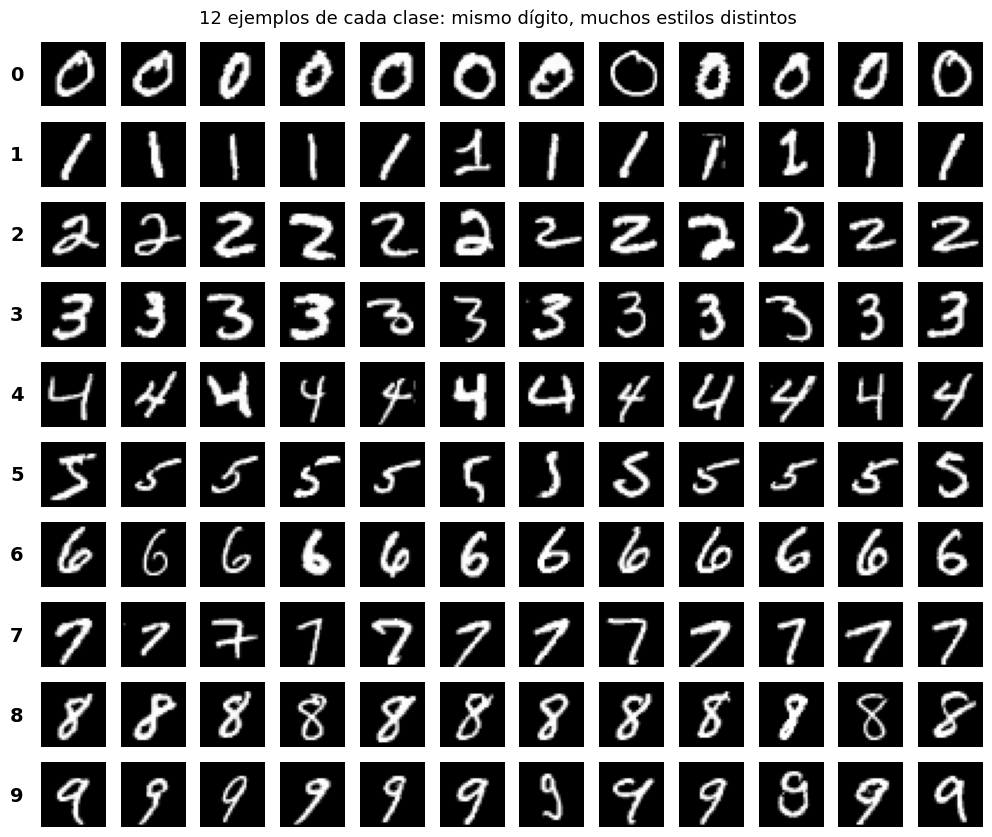

In [3]:
mnist_train = torchvision.datasets.MNIST(f"{TRABAJO}/data", train=True, download=True)   # descarga el conjunto de entrenamiento
mnist_test = torchvision.datasets.MNIST(f"{TRABAJO}/data", train=False, download=True)   # descarga el conjunto de prueba

imgs28 = mnist_train.data          # tensor uint8 (60000, 28, 28): valores de 0 (negro) a 255 (blanco)
etiq28 = mnist_train.targets       # tensor (60000,): el dígito de cada imagen
print("Entrenamiento:", tuple(imgs28.shape), "| Prueba:", tuple(mnist_test.data.shape))
print("Tipo de dato:", imgs28.dtype, "| valor mínimo:", imgs28.min().item(), "| valor máximo:", imgs28.max().item())

fig, axes = plt.subplots(10, 12, figsize=(10, 8.5))                  # 10 filas (dígitos) x 12 ejemplos
for d in range(10):                                                   # para cada dígito
    idx = torch.where(etiq28 == d)[0][:12]                            # tomamos 12 ejemplos de ese dígito
    for j, i in enumerate(idx):
        axes[d, j].imshow(imgs28[i], cmap="gray"); axes[d, j].axis("off")
    axes[d, 0].text(-8, 14, str(d), fontsize=14, va="center", ha="right", fontweight="bold")   # etiqueta a la izquierda
plt.suptitle("12 ejemplos de cada clase: mismo dígito, muchos estilos distintos", fontsize=13)
plt.tight_layout(); plt.show()

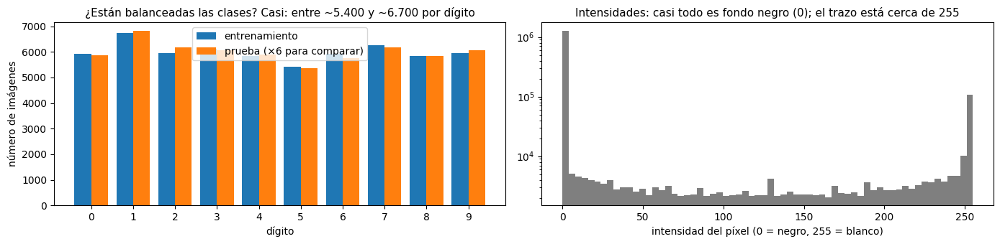

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
cuenta_train = torch.bincount(etiq28, minlength=10).numpy()                 # imágenes por clase (entrenamiento)
cuenta_test = torch.bincount(mnist_test.targets, minlength=10).numpy()      # imágenes por clase (prueba)
axes[0].bar(np.arange(10) - 0.2, cuenta_train, 0.4, label="entrenamiento")
axes[0].bar(np.arange(10) + 0.2, cuenta_test * 6, 0.4, label="prueba (×6 para comparar)")
axes[0].set_xticks(range(10)); axes[0].set_xlabel("dígito"); axes[0].set_ylabel("número de imágenes")
axes[0].set_title("¿Están balanceadas las clases? Casi: entre ~5.400 y ~6.700 por dígito"); axes[0].legend()
axes[1].hist(imgs28[:2000].flatten().numpy(), bins=64, color="tab:gray")     # histograma de intensidades
axes[1].set_yscale("log"); axes[1].set_xlabel("intensidad del píxel (0 = negro, 255 = blanco)")
axes[1].set_title("Intensidades: casi todo es fondo negro (0); el trazo está cerca de 255")
plt.tight_layout(); plt.show()

### Una imagen es solo una tabla de números

Para la computadora, un dígito no es más que una matriz de 28×28 = 784 números. Todo modelo generativo, al final, tiene que producir esa tabla de números de forma que "parezca" un dígito.

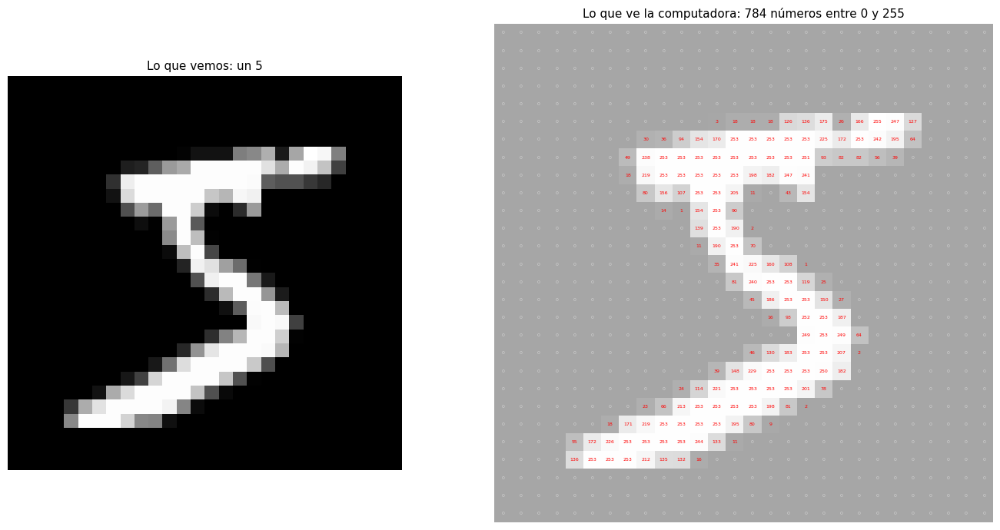

In [5]:
ejemplo = imgs28[0].numpy()                                             # tomamos una imagen
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1, 2]})
axes[0].imshow(ejemplo, cmap="gray"); axes[0].set_title(f"Lo que vemos: un {etiq28[0].item()}"); axes[0].axis("off")
axes[1].imshow(ejemplo, cmap="Greys_r", alpha=0.35)                     # la imagen de fondo, tenue
for i in range(28):                                                     # escribimos el valor de cada píxel
    for j in range(28):
        v = ejemplo[i, j]
        axes[1].text(j, i, str(v), ha="center", va="center", fontsize=4.5, color="red" if v > 0 else "lightgray")
axes[1].set_title("Lo que ve la computadora: 784 números entre 0 y 255"); axes[1].axis("off")
plt.tight_layout(); plt.show()

### Preparación de los datos

Dos cambios pequeños antes de entrenar:

1. **Relleno a 32×32**: añadimos 2 píxeles negros en cada borde. Las redes convolucionales reducen y amplían la imagen a la mitad varias veces (32 → 16 → 8 → 4), y eso es más cómodo con potencias de 2.
2. **Escala a [-1, 1]**: 0 (negro) pasa a -1 y 255 (blanco) a +1. Valores centrados en cero facilitan el entrenamiento.

Todo el conjunto (unos 250 MB) cabe en la memoria de la GPU, así que no usamos `DataLoader`: indexamos directamente el tensor, que es mucho más rápido para imágenes tan pequeñas.

In [6]:
def preparar(uint8_imgs):
    x = uint8_imgs.float().unsqueeze(1) / 255.0         # (N,28,28) -> (N,1,28,28) en [0,1]; el 1 es el canal de gris
    x = F.pad(x, (2, 2, 2, 2), value=0.0)                # rellenamos a (N,1,32,32) con borde negro
    return x * 2 - 1                                     # escalamos a [-1, 1]

X_train = preparar(mnist_train.data).to(device)          # imágenes de entrenamiento en la GPU
Y_train = mnist_train.targets.to(device)                 # etiquetas de entrenamiento en la GPU
X_test = preparar(mnist_test.data)                       # imágenes de prueba (en CPU; solo se usan para métricas)
Y_test = mnist_test.targets                              # etiquetas de prueba
print("X_train:", tuple(X_train.shape), "rango:", X_train.min().item(), "a", X_train.max().item())

def subconjunto(X, Y, fraccion, semilla=0):
    """Devuelve una fracción aleatoria (pero reproducible) de los datos."""
    n = max(1, int(len(X) * fraccion))                           # número de imágenes a conservar
    g = torch.Generator().manual_seed(semilla)                   # generador con semilla fija
    idx = torch.randperm(len(X), generator=g)[:n].to(X.device)   # índices aleatorios sin repetición
    return X[idx], Y[idx]


X_train: (60000, 1, 32, 32) rango: -1.0 a 1.0


# ¿Qué es un modelo generativo?

Llamemos $p_{\text{datos}}(x)$ a la distribución de los datos: la regla (desconocida) que dice qué tan probable es cada imagen $x$.

Un modelo generativo es una red con parámetros $\theta$ que define su propia distribución $p_\theta(x)$ y se entrena para que $p_\theta \approx p_{\text{datos}}$ usando solo ejemplos. Ya entrenado, podemos muestrear $x\sim p_\theta$: producir imágenes nuevas, que no están en el conjunto de entrenamiento, pero que podrían estarlo.

- Un modelo **discriminativo** aprende $p(y\mid x)$: "dada esta imagen, ¿qué dígito es?".
- Un modelo **generativo** aprende $p(x)$: "¿cómo son los dígitos para poder dibujar nuevos?".
- Un modelo **generativo condicional** aprende $p(x\mid y)$: "¿cómo es un 7, para poder dibujar un 7 nuevo?". Es lo que haremos en este tutorial: la etiqueta $y$ entra como una entrada más de la red.

La dificultad es que $p_{\text{datos}}$ no está escrita en ningún lado; solo tenemos ejemplos. Existen varias familias de modelos, y cada una es un truco distinto para que aprender y muestrear sean posibles. En este tutorial veremos dos, que representan dos formas muy distintas de generar:

| Familia | Año | Truco central | Cómo genera |
|---|---|---|---|
| VAE | 2013 | Aprender a transformar ruido gaussiano $z$ en imágenes con un decodificador | De una vez: una pasada por la red |
| Difusión | 2020 | Aprender a quitar ruido poco a poco | Gradualmente: decenas o cientos de pasadas por la red |

Otras familias, como las GAN o los modelos autorregresivos, quedan fuera de esta sesión.

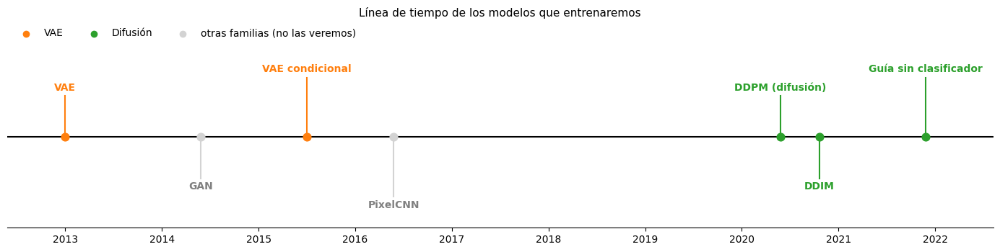

In [7]:
# A los años les he puesto valores decimales solo para que la línea de tiempo sea más facil de leer

eventos = [                                                   # (año, nombre, color) de los hitos
    (2013.0, "VAE", "tab:orange"), (2014.4, "GAN", "lightgray"), (2015.5, "VAE condicional", "tab:orange"),
    (2016.4, "PixelCNN", "lightgray"), (2020.4, "DDPM (difusión)", "tab:green"), (2020.8, "DDIM", "tab:green"),
    (2021.9, "Guía sin clasificador", "tab:green"),
]
fig, ax = plt.subplots(figsize=(14, 3.6))
ax.axhline(0, color="black", lw=1.5)                                          # línea del tiempo
for k, (anio, nombre, c) in enumerate(eventos):
    h = (1 if k % 2 == 0 else -1) * (1 + 0.45 * ((k // 2) % 2))              # altura alterna para no encimar textos
    ax.plot([anio, anio], [0, h], color=c, lw=1.5); ax.scatter([anio], [0], color=c, s=60, zorder=3)
    ax.text(anio, h + (0.08 if h > 0 else -0.08), nombre, ha="center", va="bottom" if h > 0 else "top",
            fontsize=10, color=c if c != "lightgray" else "gray", fontweight="bold")
for fam, c in [("VAE", "tab:orange"), ("Difusión", "tab:green"), ("otras familias (no las veremos)", "lightgray")]:
    ax.scatter([], [], color=c, label=fam)
ax.set_xlim(2012.4, 2022.6); ax.set_ylim(-2.2, 2.2); ax.set_yticks([]); ax.set_xticks(range(2013, 2023))
for s in ["left", "right", "top"]: ax.spines[s].set_visible(False)
ax.legend(loc="upper left", ncol=3, frameon=False, bbox_to_anchor=(0, 1.15))
ax.set_title("Línea de tiempo de los modelos que entrenaremos", pad=30); plt.tight_layout(); plt.show()

# ¿Cómo aprende una red? La función de pérdida y por qué debe ser diferenciable

Una red neuronal tiene miles o millones de parámetros $\theta$ (pesos). Aprender significa encontrar valores de $\theta$ que hagan bien la tarea. Para eso necesitamos tres ingredientes:

1. Una función de pérdida $\mathcal L(\theta)$: un único número que mide qué tan mal lo está haciendo el modelo. Traduce "lo que queremos" (dígitos realistas) en algo que se puede optimizar. Cada familia generativa se distingue, sobre todo, por la pérdida que usa.
2. El gradiente $\nabla_\theta\mathcal L$: el vector de derivadas de la pérdida respecto a cada parámetro. Indica, para cada peso, hacia dónde moverlo y cuánto para que la pérdida baje.
3. Descenso por gradiente: repetir miles de veces $\;\theta \leftarrow \theta - \eta\,\nabla_\theta\mathcal L\;$, donde $\eta$ es la tasa de aprendizaje (`lr` en el panel de control).

¿Por qué la pérdida tiene que ser diferenciable? Porque sin derivada no hay gradiente, y sin gradiente la red no sabe en qué dirección cambiar sus millones de pesos. Probar cambios al azar sería imposible con tantas dimensiones. PyTorch calcula el gradiente con retropropagación (backpropagation), que es la regla de la cadena aplicada operación por operación, desde la pérdida hasta cada peso. Por eso cada operación entre los parámetros y la pérdida debe ser diferenciable (al menos casi en todas partes, como ReLU). Si en medio hay una operación sin derivada útil, la cadena se rompe y el gradiente no llega.

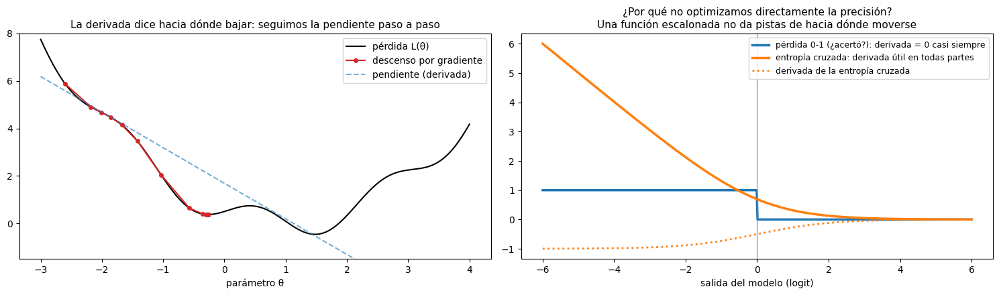

In [8]:
L = lambda t: 0.5 * (t - 1) ** 2 + 0.6 * np.sin(3 * t)          # una "pérdida" de juguete con un solo parámetro
dL = lambda t: (t - 1) + 1.8 * np.cos(3 * t)                    # su derivada (el gradiente en 1D)
theta = np.linspace(-3, 4, 400)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(theta, L(theta), color="black", label="pérdida L(θ)")
t, lr, recorrido = -2.6, 0.12, []                               # punto inicial y tasa de aprendizaje
for _ in range(25):                                             # 25 pasos de descenso por gradiente
    recorrido.append(t); t = t - lr * dL(t)                     # θ <- θ - lr * dL/dθ
recorrido = np.array(recorrido)
axes[0].plot(recorrido, L(recorrido), "o-", color="tab:red", ms=4, label="descenso por gradiente")
t0_ = recorrido[3]                                              # dibujamos la recta tangente en un punto
axes[0].plot(theta, L(t0_) + dL(t0_) * (theta - t0_), "--", color="tab:blue", alpha=0.6, label="pendiente (derivada)")
axes[0].set_ylim(-1.5, 8); axes[0].set_xlabel("parámetro θ"); axes[0].legend()
axes[0].set_title("La derivada dice hacia dónde bajar: seguimos la pendiente paso a paso")

s = np.linspace(-6, 6, 500)                                    # salida del modelo (logit) para un ejemplo de clase 1
perdida_01 = (s < 0).astype(float)                             # pérdida 0-1: 1 si se equivoca, 0 si acierta
perdida_ce = np.log1p(np.exp(-s))                              # entropía cruzada: suave
axes[1].plot(s, perdida_01, lw=2.5, label="pérdida 0-1 (¿acertó?): derivada = 0 casi siempre")
axes[1].plot(s, perdida_ce, lw=2.5, label="entropía cruzada: derivada útil en todas partes")
axes[1].plot(s, -1 / (1 + np.exp(s)), ":", color="tab:orange", lw=2, label="derivada de la entropía cruzada")
axes[1].axvline(0, color="gray", lw=0.8); axes[1].set_xlabel("salida del modelo (logit)"); axes[1].legend(fontsize=9)
axes[1].set_title("¿Por qué no optimizamos directamente la precisión?\nUna función escalonada no da pistas de hacia dónde moverse")
plt.tight_layout(); plt.show()

In [9]:
w = torch.tensor(2.0, requires_grad=True)       # un parámetro; requires_grad=True: "quiero su derivada"
x = torch.tensor(3.0)                           # un dato de entrada (no se entrena)
y_obj = torch.tensor(10.0)                      # el valor que queremos obtener
y_pred = w * x                                  # predicción del "modelo": 2 * 3 = 6
perdida = (y_pred - y_obj) ** 2                 # error cuadrático: (6 - 10)^2 = 16
perdida.backward()                              # retropropagación: calcula d(perdida)/dw
print("pérdida =", perdida.item())
print("dL/dw  =", w.grad.item(), " (a mano: 2·(w·x - y)·x = 2·(6-10)·3 = -24)")
with torch.no_grad():                           # actualizamos el parámetro sin registrar esta operación
    w -= 0.01 * w.grad                          # paso de descenso: w = 2 - 0.01·(-24) = 2.24
print("w nuevo =", w.item(), "-> la predicción se acerca a 10:", (w * x).item())

pérdida = 16.0
dL/dw  = -24.0  (a mano: 2·(w·x - y)·x = 2·(6-10)·3 = -24)
w nuevo = 2.240000009536743 -> la predicción se acerca a 10: 6.720000267028809


### El problema de la diferenciabilidad en los modelos generativos

Los modelos generativos tienen un obstáculo especial: generar implica azar, y "tirar un dado" no tiene derivada. Cada familia lo resuelve de una forma distinta, y esa solución explica buena parte de su diseño:

| Modelo | Operación problemática | Cómo se resuelve |
|---|---|---|
| **VAE** | Muestrear el código $z\sim\mathcal N(\mu,\sigma^2)$ dentro de la red | Truco de reparametrización: $z=\mu+\sigma\cdot\varepsilon$, con el azar $\varepsilon$ fuera del camino del gradiente |
| **Difusión** | Generar requiere decenas de pasos aleatorios | En el entrenamiento no se genera nada: se añade ruido conocido y la red solo aprende a predecirlo con un error cuadrático, una pérdida suave y simple |

# Herramientas comunes: entrenador, estados intermedios y GIF

Los dos modelos comparten el mismo entrenador. Cada modelo solo aporta dos funciones:
- `paso_entrenamiento(x, y)`: hace un paso de optimización con un lote y devuelve sus pérdidas;
- `snapshot()`: genera las 4 imágenes de seguimiento (dígitos `DIGITOS_GIF`, siempre con el mismo ruido de partida) con el estado actual de la red.

El entrenador respeta el panel de control (fracción de datos, épocas o tiempo), imprime el progreso, toma `N_SNAPSHOTS` estados intermedios repartidos a lo largo del entrenamiento (el tiempo que tarda generar esos estados no cuenta como tiempo de entrenamiento) y al final dibuja las curvas de pérdida.

Como la evaluación es cualitativa, la función `revisar_muestras` pone lado a lado dígitos reales y dígitos generados (una fila por dígito pedido) para compararlos a ojo.

In [10]:
def entrenar(nombre, paso_entrenamiento, snapshot, cfg):
    Xs, Ys = subconjunto(X_train, Y_train, cfg["fraccion_datos"])          # datos que usará este modelo
    bs = cfg["batch_size"]                                                  # tamaño del lote
    pasos_por_epoca = max(1, len(Xs) // bs)                                 # pasos que forman una época
    por_epocas = cfg["modo"] == "epocas"                                    # ¿paramos por épocas o por tiempo?
    total_pasos = cfg["epocas"] * pasos_por_epoca if por_epocas else None   # meta en pasos (modo épocas)
    limite_s = None if por_epocas else cfg["minutos"] * 60                  # meta en segundos (modo tiempo)
    meta = f"{cfg['epocas']} épocas" if por_epocas else f"{cfg['minutos']} min"
    print(f"[{nombre}] {len(Xs):,} imágenes ({100 * cfg['fraccion_datos']:.0f}%), "
          f"{pasos_por_epoca} pasos por época, meta: {meta}")

    historial = defaultdict(list)                                           # pérdidas de cada paso
    fotos, leyendas = [snapshot()], ["0% · inicio (red aleatoria)"]              # estado 0: antes de entrenar
    paso, t_entreno, siguiente_foto, siguiente_log = 0, 0.0, 1, 1           # contadores
    terminado = False
    while not terminado:                                                    # un ciclo = una época
        perm = torch.randperm(len(Xs), device=Xs.device)                    # barajamos los datos en cada época
        for i in range(pasos_por_epoca):
            idx = perm[i * bs:(i + 1) * bs]                                 # índices del lote
            t0 = time.time()
            perdidas = paso_entrenamiento(Xs[idx], Ys[idx])                 # UN paso de optimización
            t_entreno += time.time() - t0                                   # solo contamos el tiempo de entrenar
            paso += 1
            for k, v in perdidas.items(): historial[k].append(v)            # guardamos las pérdidas
            progreso = paso / total_pasos if por_epocas else t_entreno / limite_s   # fracción completada (0 a 1)
            epoca = math.ceil(paso / pasos_por_epoca)                       # época en curso (número entero: 1, 2, 3...)
            if progreso >= siguiente_foto / N_SNAPSHOTS:                    # ¿toca guardar un estado intermedio?
                fotos.append(snapshot())
                leyendas.append(f"{100 * siguiente_foto / N_SNAPSHOTS:.0f}% · época {epoca} · {t_entreno:.0f} s")
                siguiente_foto += 1
            if progreso >= siguiente_log / 10:                              # imprimimos cada 10% de progreso
                resumen = " | ".join(f"{k} {np.mean(v[-100:]):.4f}" for k, v in historial.items())
                print(f"  {100 * min(progreso, 1):5.0f}% · paso {paso:6d} · época {epoca:3d} · {t_entreno:5.0f} s · {resumen}")
                siguiente_log += 1
            if progreso >= 1: terminado = True; break                       # meta alcanzada
    while len(fotos) < N_SNAPSHOTS + 1:                                     # garantizamos el estado final
        fotos.append(snapshot()); leyendas.append(f"100% · época {epoca} · {t_entreno:.0f} s")
    graficar_historial(historial, nombre)
    return dict(historial=historial, fotos=fotos, leyendas=leyendas, tiempo_s=t_entreno,
                pasos=paso, epocas=paso / pasos_por_epoca, n_datos=len(Xs))

def graficar_historial(historial, nombre, ventana=100):
    claves = list(historial)
    fig, axes = plt.subplots(1, len(claves), figsize=(4.2 * len(claves), 3))
    for ax, k in zip(np.atleast_1d(axes), claves):
        v = pd.Series(historial[k])
        ax.plot(v, alpha=0.2, color="tab:blue")                                  # valor de cada paso
        ax.plot(v.rolling(ventana, min_periods=1).mean(), color="tab:blue")      # media móvil
        ax.set_title(k); ax.set_xlabel("paso")
    plt.suptitle(f"{nombre}: curvas de entrenamiento", y=1.03); plt.tight_layout(); plt.show()

In [11]:
def a_imagen(t):                                             # tensor (C,H,W) en [-1,1] -> arreglo HxWx3 en [0,1]
    t = ((t.float().cpu() + 1) / 2).clamp(0, 1)
    return t.repeat(3, 1, 1).permute(1, 2, 0).numpy() if t.shape[0] == 1 else t.permute(1, 2, 0).numpy()

def mostrar(imgs, nrow=8, titulo=None, tam=5, ax=None):
    grid = make_grid(imgs.detach().float().cpu(), nrow=nrow, normalize=True, value_range=(-1, 1), pad_value=1.0)
    propio = ax is None
    if propio: plt.figure(figsize=(tam, tam)); ax = plt.gca()
    ax.imshow(grid.permute(1, 2, 0).numpy()); ax.axis("off")
    if titulo: ax.set_title(titulo)
    if propio: plt.show()

def mostrar_por_digito(fn_generar, n_por_digito=8, titulo="", tam=6):
    """Filas = dígitos 0..9 pedidos al modelo; columnas = muestras distintas."""
    etiquetas = torch.arange(10).repeat_interleave(n_por_digito)              # 0,0,...,1,1,...,9
    imgs = fn_generar(etiquetas)
    mostrar(imgs, nrow=n_por_digito, titulo=titulo, tam=tam)
    return imgs

def fuente(tam=15):
    try: return ImageFont.load_default(size=tam)             # Pillow >= 10.1
    except TypeError: return ImageFont.load_default()

def guardar_gif(frames, leyendas, ruta, ncol=4, nombres_filas=None, escala=4, ms=None):
    """frames: lista de tensores (N,C,32,32). Cada frame es un mosaico de ncol columnas."""
    if ms is None: ms = int(np.clip(10000 / len(frames), 60, 500))   # duración por cuadro: el GIF completo dura ~10 s
    imgs_pil = []
    margen = 110 if nombres_filas else 0                     # espacio a la izquierda para nombres de fila
    for f, texto in zip(frames, leyendas):
        grid = make_grid(f.float().cpu(), nrow=ncol, normalize=True, value_range=(-1, 1), pad_value=1, padding=2)
        arr = (grid.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
        im = Image.fromarray(arr).resize((arr.shape[1] * escala, arr.shape[0] * escala), Image.NEAREST)
        lienzo = Image.new("RGB", (im.width + margen, im.height + 34), "white")
        lienzo.paste(im, (margen, 34))
        d = ImageDraw.Draw(lienzo)
        d.text((6, 8), sin_tildes(texto), fill="black", font=fuente())
        if nombres_filas:
            alto_fila = im.height / len(nombres_filas)
            for k, n in enumerate(nombres_filas):
                d.text((6, 34 + alto_fila * (k + 0.45)), sin_tildes(n), fill="black", font=fuente(14))
        imgs_pil.append(lienzo)
    imgs_pil += [imgs_pil[-1]] * 4                           # pausa al final antes de repetir
    imgs_pil[0].save(ruta, save_all=True, append_images=imgs_pil[1:], duration=ms, loop=0)
    display(IPImage(filename=ruta))
    print("GIF guardado en:", ruta)

def sin_tildes(s):                                           # la fuente por defecto de PIL puede no tener tildes
    return s.translate(str.maketrans("áéíóúñÁÉÍÓÚÑ·", "aeiounAEIOUN-"))

def mostrar_evolucion(res, nombre, max_filas=7):
    """Matriz estática: filas = momentos del entrenamiento, columnas = las 4 imágenes seguidas."""
    sel = np.unique(np.linspace(0, len(res["fotos"]) - 1, max_filas).round().astype(int))
    fig, axes = plt.subplots(len(sel), 4, figsize=(6.2, 1.55 * len(sel)))
    for r, k in enumerate(sel):
        for c in range(4):
            axes[r, c].imshow(a_imagen(res["fotos"][k][c])); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
            if r == 0: axes[r, c].set_title(f"pedido: {DIGITOS_GIF[c]}")
        axes[r, 0].set_ylabel(res["leyendas"][k], rotation=0, ha="right", va="center", fontsize=9)
    plt.suptitle(f"{nombre}: evolución de las mismas 4 generaciones durante el entrenamiento", y=1.0)
    plt.tight_layout(); plt.show()

def diagrama(cajas, flechas, titulo, tam=(13, 3.2)):
    """Dibuja un esquema: cajas = {id: (x, y, texto, color)}, flechas = [(origen, destino, rótulo)]."""
    fig, ax = plt.subplots(figsize=tam)
    for x, y, texto, color in cajas.values():
        ax.text(x, y, texto, ha="center", va="center", fontsize=10,
                bbox=dict(boxstyle="round,pad=0.6", fc=color, ec="black", lw=1))
    for a, b, rot in flechas:
        (xa, ya), (xb, yb) = cajas[a][:2], cajas[b][:2]
        ax.annotate("", xy=(xb, yb), xytext=(xa, ya),
                    arrowprops=dict(arrowstyle="-|>", lw=1.6, color="dimgray", shrinkA=38, shrinkB=38))
        if rot: ax.text((xa + xb) / 2, (ya + yb) / 2 + 0.16, rot, ha="center", fontsize=8.5, color="dimgray", style="italic")
    xs = [c[0] for c in cajas.values()]; ys = [c[1] for c in cajas.values()]
    ax.set_xlim(min(xs) - 0.8, max(xs) + 0.8); ax.set_ylim(min(ys) - 0.7, max(ys) + 0.7); ax.axis("off")
    ax.set_title(titulo, fontsize=12); plt.show()

ETIQ_GIF = torch.tensor(DIGITOS_GIF)                         # etiquetas de las 4 imágenes de seguimiento
MUESTRAS = {}                                                # imágenes generadas por cada modelo (para la comparación final)
RES = {}                                                     # resultados de entrenamiento de cada modelo

def revisar_muestras(nombre, fn_generar, n_por_digito=8):
    """Evaluación cualitativa: reales (izquierda) y generadas (derecha), una fila por dígito."""
    etiquetas = torch.arange(10).repeat_interleave(n_por_digito)              # 0,0,...,1,1,...,9
    t0 = time.time()
    generadas = fn_generar(etiquetas)                                         # pedimos n imágenes de cada dígito
    dt = time.time() - t0
    reales = torch.cat([X_test[Y_test == d][:n_por_digito] for d in range(10)])   # las mismas cantidades, reales
    fig, axes = plt.subplots(1, 2, figsize=(13, 7))
    mostrar(reales, nrow=n_por_digito, ax=axes[0], titulo="dígitos reales (prueba)")
    mostrar(generadas, nrow=n_por_digito, ax=axes[1], titulo=f"{nombre}: generados (fila = dígito pedido 0..9)")
    plt.suptitle(f"{nombre}: {len(generadas)} imágenes generadas en {1000 * dt:.1f} ms ({1000 * dt / len(generadas):.2f} ms por imagen)", fontsize=12)
    plt.tight_layout(); plt.show()
    MUESTRAS[nombre] = (etiquetas, generadas)
    return generadas

### ¿Cómo revisar las muestras?

Sin métricas, la evaluación es una inspección guiada. Para cada fila (dígito pedido) nos preguntamos:

1. ¿Parece un dígito escrito a mano, o hay manchas y trazos sin sentido?
2. ¿Es el dígito que pedimos?
3. ¿Hay variedad (grosor, inclinación, tamaño), o las 8 muestras son casi iguales?
4. ¿Los bordes son nítidos como en los reales, o se ven borrosos?

# Autoencoder variacional condicional (VAE: Kingma & Welling 2013; CVAE: Sohn et al. 2015)

En una frase: comprimir cada imagen en un código aleatorio pequeño $z$, aprender a reconstruirla desde ese código, y obligar a que los códigos de todas las imágenes se parezcan a una gaussiana estándar, para que cualquier muestra gaussiana se decodifique en una imagen plausible.

Punto de partida: el autoencoder. Un codificador resume la imagen en pocos números $z$ y un decodificador la reconstruye. Aprende buenos códigos, pero no genera: los códigos de los dígitos reales forman una nube irregular, y un $z$ al azar suele caer en una zona vacía que se decodifica como basura. El VAE corrige eso.

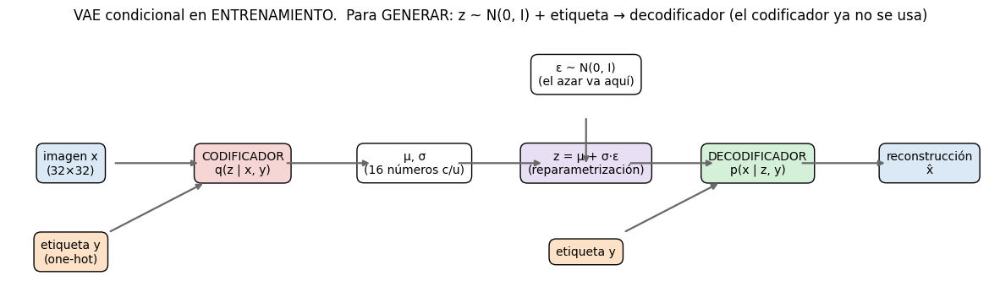

In [12]:
diagrama(
    {"x": (0, 0, "imagen x\n(32×32)", "#dbe9f6"), "y1": (0, -1.3, "etiqueta y\n(one-hot)", "#fde2c8"),
     "enc": (2.2, 0, "CODIFICADOR\nq(z | x, y)", "#f6d5d5"), "musig": (4.4, 0, "μ, σ\n(16 números c/u)", "white"),
     "z": (6.6, 0, "z = μ + σ·ε\n(reparametrización)", "#e8dff5"), "eps": (6.6, 1.3, "ε ~ N(0, I)\n(el azar va aquí)", "white"),
     "y2": (6.6, -1.3, "etiqueta y", "#fde2c8"), "dec": (8.8, 0, "DECODIFICADOR\np(x | z, y)", "#d5f0d8"),
     "xr": (11, 0, "reconstrucción\nx̂", "#dbe9f6")},
    [("x", "enc", ""), ("y1", "enc", ""), ("enc", "musig", ""), ("musig", "z", ""), ("eps", "z", ""),
     ("z", "dec", ""), ("y2", "dec", ""), ("dec", "xr", "")],
    "VAE condicional en ENTRENAMIENTO.  Para GENERAR: z ~ N(0, I) + etiqueta → decodificador (el codificador ya no se usa)",
    tam=(15, 4.2))

¿Qué aprende? Dos redes:
- un codificador $q_\phi(z\mid x,y)=\mathcal N\big(\mu_\phi(x,y),\,\sigma_\phi^2(x,y)\big)$: para cada imagen, una pequeña "nube" gaussiana de códigos posibles;
- un decodificador $p_\theta(x\mid z,y)$: dada una etiqueta y un código, la probabilidad de que cada píxel tenga tinta.

Como la etiqueta ya dice qué dígito es, el código $z$ termina guardando el estilo (grosor, inclinación, tamaño). Lo comprobaremos visualmente.

¿Cómo aprende? Maximiza la ELBO (Evidence Lower BOund), una cota inferior de $\log p_\theta(x\mid y)$; en la práctica minimizamos su negativo:
$$
\mathcal L_{\text{VAE}}=\underbrace{-\,\mathbb E_{q}\big[\log p_\theta(x\mid z,y)\big]}_{\text{reconstrucción: entropía cruzada píxel a píxel}}\;+\;\underbrace{\mathrm{KL}\big(q_\phi(z\mid x,y)\,\Vert\,\mathcal N(0,I)\big)}_{\text{regularización: códigos cerca de la gaussiana estándar}}
$$
- Para qué sirve cada término: el primero obliga a que el código conserve la información de la imagen; el segundo obliga a que todos los códigos vivan en la misma región, sin huecos, para que al generar con $z\sim\mathcal N(0,I)$ caigamos siempre en zona "conocida". Para gaussianas, la KL tiene fórmula cerrada: $\tfrac12\sum_j(\mu_j^2+\sigma_j^2-\log\sigma_j^2-1)$.
- Por qué es diferenciable: la entropía cruzada y la KL son funciones suaves de $\mu$, $\sigma$ y de la salida del decodificador. El único obstáculo es muestrear $z$: la operación "sacar un número al azar de $\mathcal N(\mu,\sigma^2)$" no tiene derivada respecto a $\mu$ y $\sigma$. El truco de reparametrización la reescribe como $z=\mu+\sigma\cdot\varepsilon$ con $\varepsilon\sim\mathcal N(0,I)$: el azar queda en $\varepsilon$, que no depende de ningún parámetro, y $z$ pasa a ser una suma y un producto, perfectamente derivables.

¿Cómo genera? Se elige la etiqueta $y$, se toma $z\sim\mathcal N(0,I)$ y se aplica el decodificador una sola vez. Es rapidísimo.

Debilidad conocida: el término de reconstrucción promedia todas las imágenes compatibles con un código, así que las muestras suelen salir borrosas.

In [13]:
class VAECondicional(nn.Module):
    def __init__(self, dim_z=16, n_clases=10):
        super().__init__()                                              # inicializa nn.Module
        self.dim_z = dim_z                                              # tamaño del código latente z
        self.codificador = nn.Sequential(                               # imagen -> vector de características
            nn.Conv2d(1, 32, 4, 2, 1), nn.LeakyReLU(0.2),               # 1×32×32 -> 32×16×16
            nn.Conv2d(32, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.LeakyReLU(0.2),    # -> 64×8×8
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),  # -> 128×4×4
            nn.Flatten())                                               # -> vector de 128·4·4 = 2048
        self.a_mu = nn.Linear(2048 + n_clases, dim_z)                   # (características, etiqueta) -> media μ
        self.a_logvar = nn.Linear(2048 + n_clases, dim_z)               # (características, etiqueta) -> log σ²
        self.desde_z = nn.Linear(dim_z + n_clases, 2048)                # (z, etiqueta) -> vector de 2048
        self.decodificador = nn.Sequential(                             # vector -> imagen
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(),  # 128×4×4 -> 64×8×8
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.BatchNorm2d(32), nn.ReLU(),   # -> 32×16×16
            nn.ConvTranspose2d(32, 1, 4, 2, 1))                         # -> 1×32×32 (logits: "tinta sí/no")

    def codificar(self, x, y1h):
        h = self.codificador(x)                                         # características de la imagen
        h = torch.cat([h, y1h], dim=1)                                  # les pegamos la etiqueta
        return self.a_mu(h), self.a_logvar(h)                           # parámetros de la gaussiana q(z|x,y)

    def decodificar(self, z, y1h):
        h = self.desde_z(torch.cat([z, y1h], dim=1))                    # combinamos código y etiqueta
        return self.decodificador(h.view(-1, 128, 4, 4))                # lo reorganizamos como mapa 4×4 y ampliamos

    def forward(self, x, y1h):
        mu, logvar = self.codificar(x, y1h)                             # 1) codificamos
        eps = torch.randn_like(mu)                                      # 2) azar SIN parámetros: ε ~ N(0, I)
        z = mu + torch.exp(0.5 * logvar) * eps                          # 3) reparametrización: z = μ + σ·ε
        return self.decodificar(z, y1h), mu, logvar                     # 4) reconstruimos

fijar_semilla(0)
vae = VAECondicional().to(device)                                       # creamos el modelo en la GPU
opt_vae = torch.optim.Adam(vae.parameters(), lr=CONFIG["vae"]["lr"])    # optimizador Adam
n_param_vae = sum(p.numel() for p in vae.parameters())
print(f"Parámetros del VAE: {n_param_vae / 1e6:.2f} M")

Parámetros del VAE: 0.45 M


## Entrenamiento paso a paso

Un paso de entrenamiento del VAE, con un lote de imágenes reales y sus etiquetas, es:

1. **Codificar.** El codificador recibe la imagen $x$ y su etiqueta $y$ y devuelve dos vectores de 16 números: la media $\mu$ y la desviación $\sigma$ de una gaussiana. Es la "nube" de códigos posibles para esa imagen.
2. **Sortear el ruido.** Tomamos $\varepsilon\sim\mathcal N(0,I)$, 16 números al azar que no dependen de la red.
3. **Construir el código (reparametrización).** $z=\mu+\sigma\cdot\varepsilon$: un punto dentro de la nube.
4. **Decodificar.** El decodificador recibe $z$ y la etiqueta $y$ y devuelve, para cada píxel, la probabilidad de que tenga tinta: la reconstrucción $\hat x$.
5. **Calcular la pérdida.** Reconstrucción (qué tan distinta es $\hat x$ de $x$) + KL (qué tan lejos está la nube $\mathcal N(\mu,\sigma^2)$ de $\mathcal N(0,I)$).
6. **Retropropagar.** `perdida.backward()` calcula cuánto contribuyó cada peso del codificador y del decodificador al error.
7. **Actualizar.** `optimizador.step()` mueve cada peso un poco en la dirección que reduce la pérdida.

Este ciclo se repite miles de veces. Antes de entrenar, veamos qué entra y qué sale de los pasos 1 a 5 con 4 imágenes, con la red todavía aleatoria: la imagen de entrada, la reconstrucción y la pérdida.

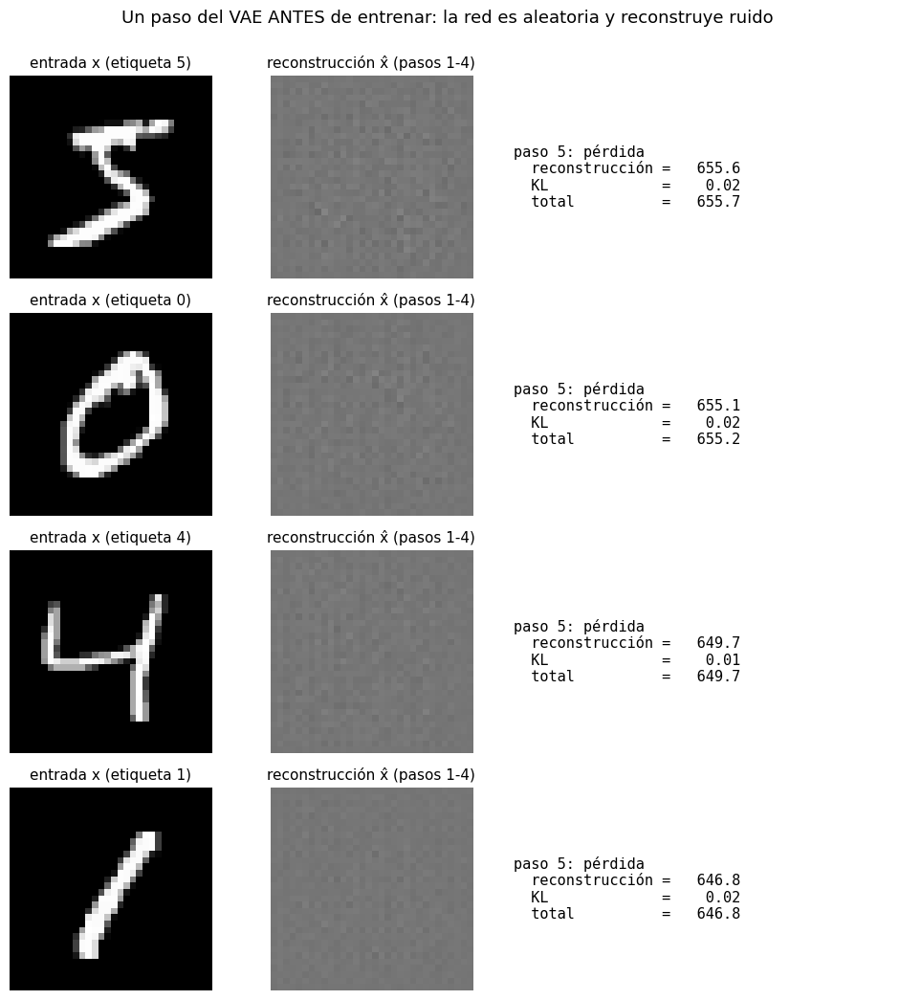

In [14]:
def anatomia_paso_vae(x, y, titulo):
    """Muestra los pasos 1 a 5 de un paso de entrenamiento del VAE, imagen por imagen."""
    y1h = F.one_hot(y, 10).float()                                        # etiqueta en formato one-hot
    with torch.no_grad():
        mu, logvar = vae.codificar(x, y1h)                                # paso 1: parámetros de la nube de códigos
        sigma = torch.exp(0.5 * logvar)                                   # desviación estándar σ
        eps = torch.randn_like(mu)                                        # paso 2: ruido sin parámetros
        z = mu + sigma * eps                                              # paso 3: reparametrización
        prob = torch.sigmoid(vae.decodificar(z, y1h))                     # paso 4: probabilidad de tinta por píxel
        objetivo = (x + 1) / 2                                            # imagen real en [0, 1]
        rec = F.binary_cross_entropy(prob, objetivo, reduction="none").sum((1, 2, 3))   # paso 5a: reconstrucción
        kl = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(1)        # paso 5b: KL
    fig, axes = plt.subplots(len(x), 3, figsize=(10, 2.6 * len(x)), gridspec_kw={"width_ratios": [1, 1, 1.6]})
    for i in range(len(x)):
        axes[i, 0].imshow(a_imagen(x[i])); axes[i, 0].set_title(f"entrada x (etiqueta {y[i].item()})")
        axes[i, 1].imshow(a_imagen(prob[i] * 2 - 1)); axes[i, 1].set_title("reconstrucción x̂ (pasos 1-4)")
        axes[i, 2].text(0.02, 0.5, f"paso 5: pérdida\n  reconstrucción = {rec[i].item():7.1f}\n  KL             = {kl[i].item():7.2f}\n"
                        f"  total          = {(rec[i] + kl[i]).item():7.1f}", fontsize=11, va="center", family="monospace")
        for c in range(3): axes[i, c].axis("off")
    plt.suptitle(titulo, fontsize=13, y=1.0); plt.tight_layout(); plt.show()

x_demo, y_demo = X_train[:4], Y_train[:4]                                  # 4 imágenes fijas para comparar antes/después
vae.eval()
anatomia_paso_vae(x_demo, y_demo, "Un paso del VAE ANTES de entrenar: la red es aleatoria y reconstruye ruido")

Los pasos 6 y 7 son los que producen el aprendizaje. Hagamos uno solo sobre un lote y midamos la pérdida del mismo lote antes y después de actualizar los pesos:

In [15]:
x, y = X_train[:128], Y_train[:128]                                       # un lote fijo
y1h = F.one_hot(y, 10).float()
vae.train()
logits, mu, logvar = vae(x, y1h)                                          # pasos 1 a 4
rec = F.binary_cross_entropy_with_logits(logits, (x + 1) / 2, reduction="sum") / len(x)
kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / len(x)
perdida = rec + kl                                                        # paso 5
opt_vae.zero_grad(set_to_none=True)
perdida.backward()                                                        # paso 6: gradientes
peso = vae.decodificador[-1].weight                                       # miramos un peso concreto de la última capa
print(f"Pérdida antes del paso: {perdida.item():.1f}")
print(f"Un peso de la última capa: {peso.view(-1)[0].item():+.5f} | su gradiente: {peso.grad.view(-1)[0].item():+.5f}")
opt_vae.step()                                                            # paso 7: actualización
print(f"El mismo peso después del paso: {peso.view(-1)[0].item():+.5f}")
with torch.no_grad():
    logits, mu, logvar = vae(x, y1h)
    nueva = (F.binary_cross_entropy_with_logits(logits, (x + 1) / 2, reduction="sum") / len(x)
             - 0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / len(x))
print(f"Pérdida del mismo lote después del paso: {nueva.item():.1f}  -> bajó: la red aprendió un poquito")

Pérdida antes del paso: 848.1
Un peso de la última capa: +0.13665 | su gradiente: +38.23197
El mismo peso después del paso: +0.13565
Pérdida del mismo lote después del paso: 788.9  -> bajó: la red aprendió un poquito


Ahora repetimos ese ciclo miles de veces con el entrenador. La función `paso_vae` es exactamente el procedimiento anterior, pasos 1 a 7:

[VAE condicional] 60,000 imágenes (100%), 468 pasos por época, meta: 8.0 min
     10% · paso   7843 · época  17 ·    48 s · -ELBO 94.2059 | reconstrucción 73.8996 | KL 20.3064
     20% · paso  15569 · época  34 ·    96 s · -ELBO 91.9845 | reconstrucción 71.9980 | KL 19.9865
     30% · paso  23352 · época  50 ·   144 s · -ELBO 90.8428 | reconstrucción 71.0555 | KL 19.7873
     40% · paso  31169 · época  67 ·   192 s · -ELBO 89.8846 | reconstrucción 70.1434 | KL 19.7412
     50% · paso  38928 · época  84 ·   240 s · -ELBO 89.4815 | reconstrucción 69.7575 | KL 19.7240
     60% · paso  46737 · época 100 ·   288 s · -ELBO 88.9863 | reconstrucción 69.3646 | KL 19.6217
     70% · paso  54520 · época 117 ·   336 s · -ELBO 88.7745 | reconstrucción 69.1215 | KL 19.6530
     80% · paso  62280 · época 134 ·   384 s · -ELBO 88.8929 | reconstrucción 69.2088 | KL 19.6842
     90% · paso  70047 · época 150 ·   432 s · -ELBO 88.6671 | reconstrucción 69.0043 | KL 19.6628
    100% · paso  77809 · época 1

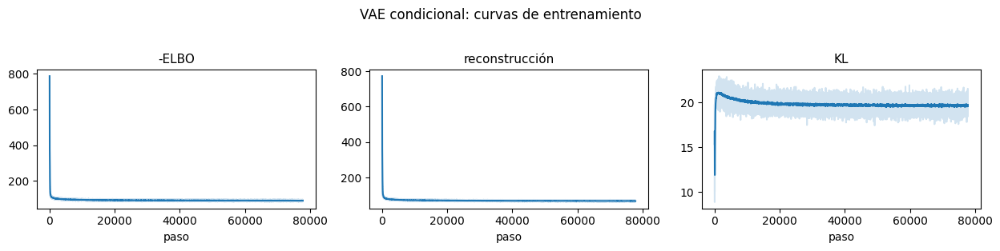

In [16]:
def paso_vae(x, y):
    vae.train()                                                          # modo entrenamiento (BatchNorm usa el lote)
    y1h = F.one_hot(y, 10).float()                                       # etiqueta -> vector one-hot de 10 posiciones
    logits, mu, logvar = vae(x, y1h)                                     # reconstrucción y parámetros de q(z|x,y)
    objetivo = (x + 1) / 2                                               # píxeles de [-1,1] a [0,1] ("probabilidad de tinta")
    rec = F.binary_cross_entropy_with_logits(logits, objetivo, reduction="sum") / x.size(0)   # reconstrucción, por imagen
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)                  # KL, por imagen
    perdida = rec + kl                                                   # -ELBO: lo que minimizamos
    opt_vae.zero_grad(set_to_none=True)                                  # borramos los gradientes del paso anterior
    perdida.backward()                                                   # retropropagación: dL/dθ para cada peso
    opt_vae.step()                                                       # actualizamos los pesos
    return {"-ELBO": perdida.item(), "reconstrucción": rec.item(), "KL": kl.item()}

@torch.no_grad()                                                         # generar no necesita gradientes
def generar_vae(etiquetas, z=None):
    vae.eval()                                                           # modo evaluación (BatchNorm usa sus promedios)
    etiquetas = etiquetas.to(device)
    if z is None: z = torch.randn(len(etiquetas), vae.dim_z, device=device)   # z ~ N(0, I)
    logits = vae.decodificar(z, F.one_hot(etiquetas, 10).float())       # UNA pasada por el decodificador
    return (torch.sigmoid(logits) * 2 - 1).cpu()                         # probabilidad de tinta -> [-1,1]

Z_GIF_VAE = torch.randn(4, vae.dim_z, device=device)                     # ruido fijo para las 4 imágenes de seguimiento
res_vae = entrenar("VAE condicional", paso_vae, lambda: generar_vae(ETIQ_GIF, Z_GIF_VAE), CONFIG["vae"])

Leyendo las curvas: la reconstrucción baja rápido (la red aprende a copiar la imagen a través del cuello de botella) mientras que la KL sube al principio: el modelo "gasta" información en el código porque le sirve para reconstruir. El equilibrio entre ambos términos es la ELBO.

### Evolución durante el entrenamiento

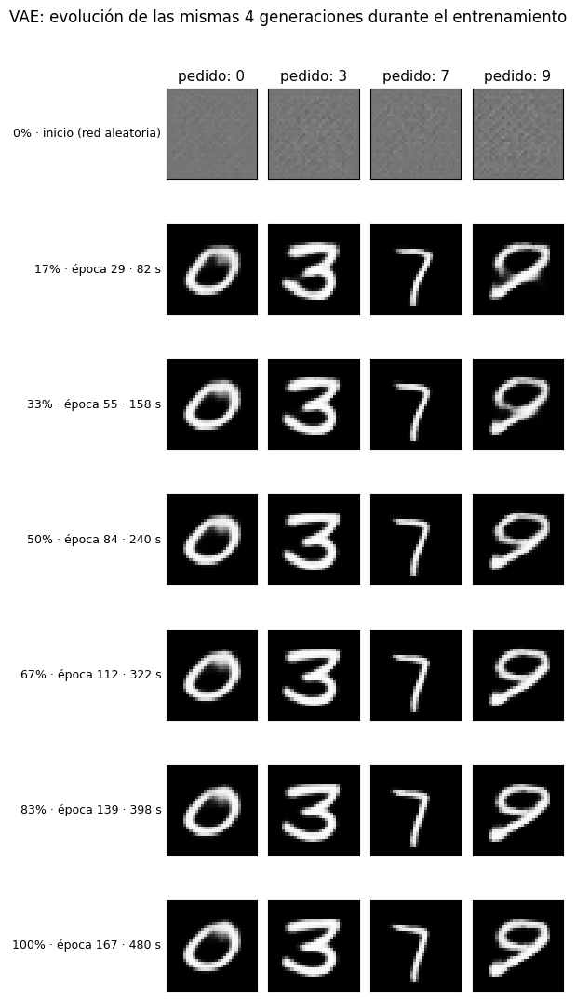

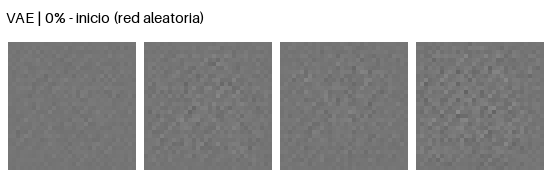

GIF guardado en: /kaggle/working/gifs/evolucion_vae.gif


In [17]:
mostrar_evolucion(res_vae, "VAE")
guardar_gif(res_vae["fotos"], [f"VAE | {l}" for l in res_vae["leyendas"]], f"{TRABAJO}/gifs/evolucion_vae.gif")

Veamos el mismo paso de entrenamiento sobre las mismas 4 imágenes, ahora con la red entrenada:

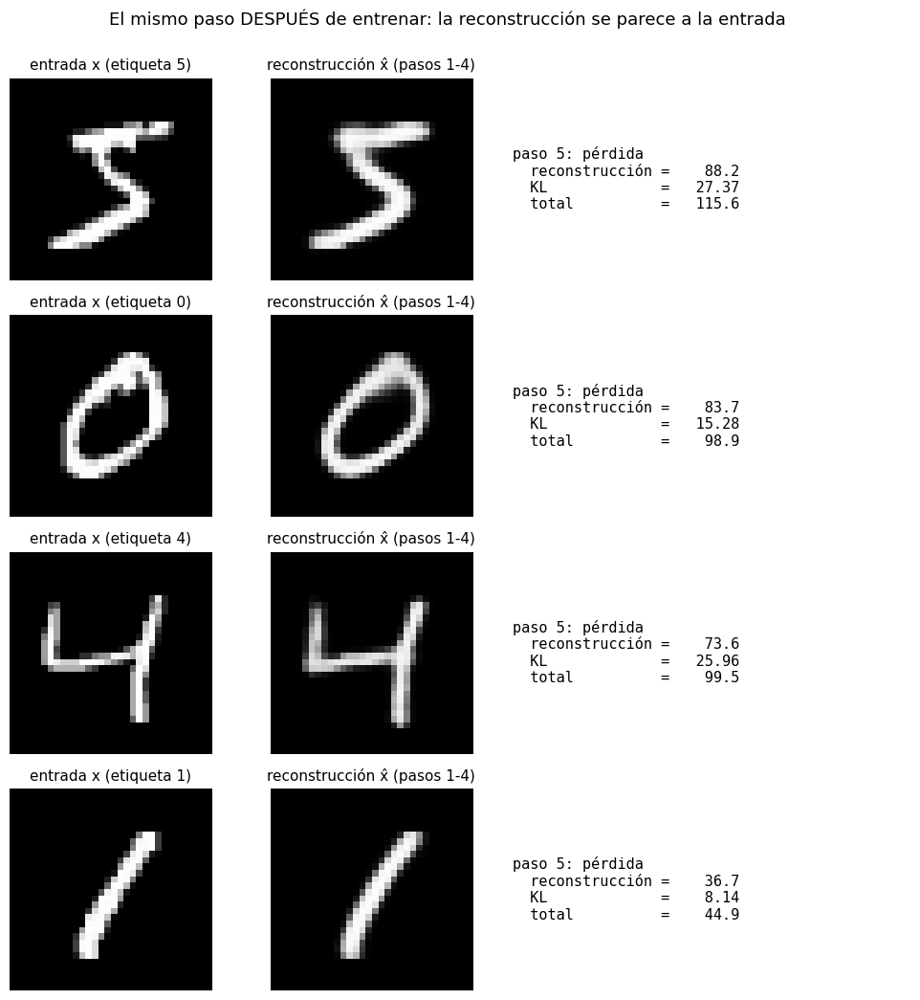

In [18]:
vae.eval()
anatomia_paso_vae(x_demo, y_demo, "El mismo paso DESPUÉS de entrenar: la reconstrucción se parece a la entrada")

## Generación paso a paso

Para generar ya no se usa el codificador ni ninguna imagen real. Solo el decodificador:

1. **Elegir la etiqueta** $y$: el dígito que queremos (por ejemplo, un 7), en formato one-hot.
2. **Sortear el código** $z\sim\mathcal N(0,I)$: 16 números al azar. Gracias a la KL, cualquier $z$ así cae en una zona que el decodificador conoce. El código decide el estilo.
3. **Capa lineal.** $[z, y]$ (26 números) se transforma en 2048 números y se reorganiza como 128 mapas de 4×4 píxeles: un "boceto" muy grueso.
4. **Ampliar a 8×8** (convolución transpuesta): la red empieza a decidir dónde va el trazo.
5. **Ampliar a 16×16.**
6. **Ampliar a 32×32** y aplicar una sigmoide: la probabilidad de tinta de cada píxel. Esa es la imagen generada.

Todo ocurre en una sola pasada por la red. Veamos qué hay dentro del decodificador en cada etapa (promediando sus canales), al generar un 7 y un 3 con el mismo código $z$. Las primeras etapas son borrosas y gruesas; cada ampliación define mejor el trazo.

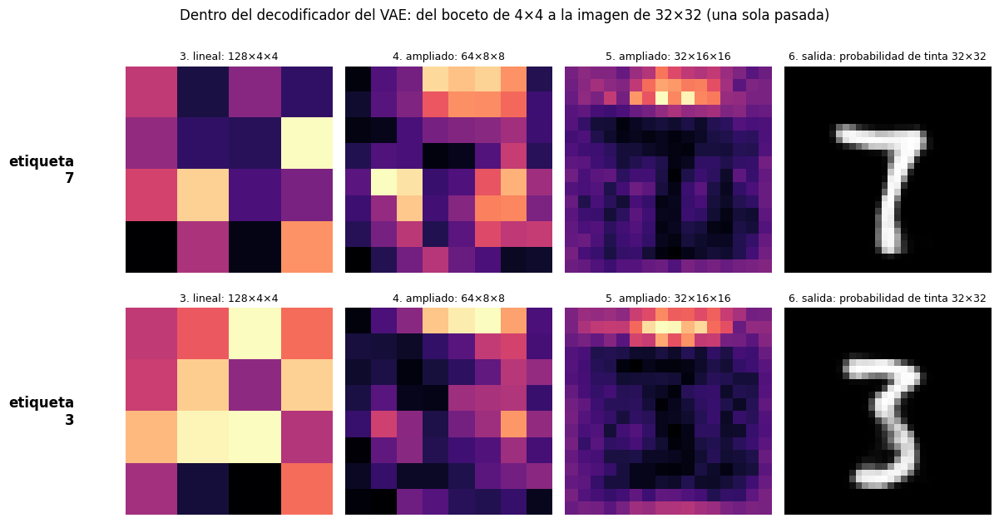

In [19]:
@torch.no_grad()
def etapas_decodificador(z, y):
    """Recorre el decodificador capa por capa y guarda lo que produce cada etapa."""
    vae.eval()
    y1h = F.one_hot(y.to(device), 10).float()                              # paso 1: etiqueta
    h = vae.desde_z(torch.cat([z, y1h], dim=1)).view(-1, 128, 4, 4)       # paso 3: lineal -> 128 mapas de 4×4
    etapas = [("3. lineal: 128×4×4", h)]
    capas = list(vae.decodificador)
    for k, capa in enumerate(capas):                                       # pasos 4-6: ConvTranspose + BN + ReLU
        h = capa(h)
        if isinstance(capa, nn.ReLU):
            etapas.append((f"{len(etapas) + 3}. ampliado: {h.shape[1]}×{h.shape[2]}×{h.shape[3]}", h))
    etapas.append(("6. salida: probabilidad de tinta 32×32", torch.sigmoid(h)))   # paso 6
    return etapas

z = torch.randn(1, vae.dim_z, device=device)                               # paso 2: un único código (un estilo)
digitos = [7, 3]                                                           # paso 1: dos etiquetas distintas
fig, axes = plt.subplots(len(digitos), 4, figsize=(12, 3.2 * len(digitos)))
for r, digito in enumerate(digitos):
    etapas = etapas_decodificador(z, torch.tensor([digito]))              # pasos 3 a 6
    for c, (nombre, h) in enumerate(etapas):
        mapa = h[0].mean(0).cpu() if h.shape[1] > 1 else h[0, 0].cpu()     # promedio de los canales de esa etapa
        axes[r, c].imshow(mapa, cmap="magma" if h.shape[1] > 1 else "gray"); axes[r, c].axis("off")
        axes[r, c].set_title(nombre, fontsize=9)
    axes[r, 0].text(-1.5, 1.5, f"etiqueta\n{digito}", ha="right", va="center", fontsize=12, fontweight="bold")
plt.suptitle("Dentro del decodificador del VAE: del boceto de 4×4 a la imagen de 32×32 (una sola pasada)", y=1.0)
plt.tight_layout(); plt.show()


## Evaluación cualitativa del VAE

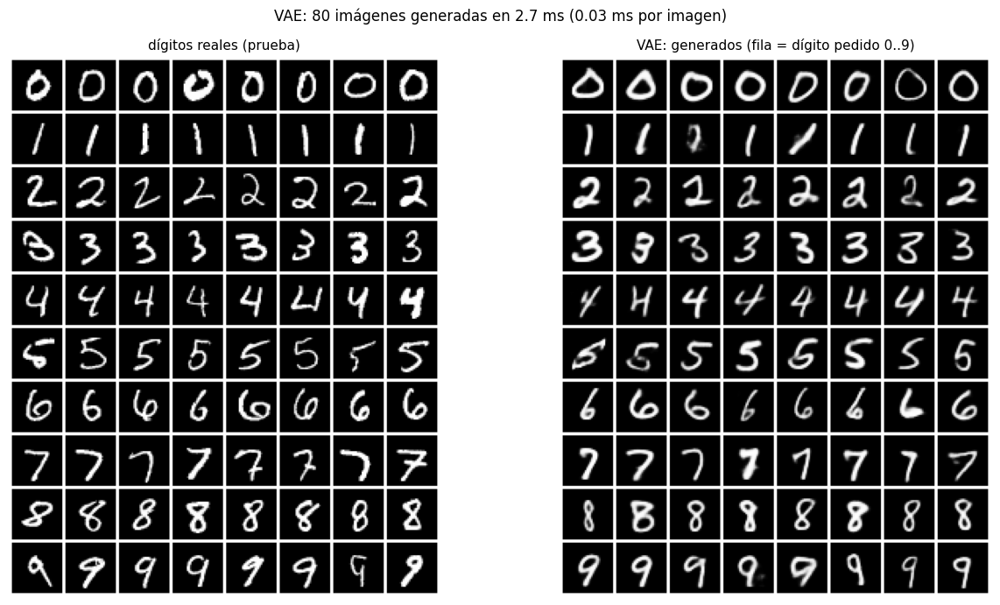

In [20]:
revisar_muestras("VAE", generar_vae)
RES["VAE"] = res_vae

Lo típico en el VAE: los dígitos se reconocen y respetan la etiqueta, y hay variedad de estilos, pero los bordes son suaves o borrosos comparados con los reales. Es la consecuencia del término de reconstrucción, que promedia las posibles imágenes compatibles con un mismo código.

# Modelos de difusión: DDPM (Ho et al., 2020), DDIM (Song et al., 2020) y guía sin clasificador (Ho & Salimans, 2021)

En una frase: destruir las imágenes añadiendo ruido poco a poco, y entrenar una red para deshacer un pequeño paso de esa destrucción; para generar, se parte de ruido puro y se aplica el paso inverso muchas veces.

## El proceso directo: añadir ruido (fijo, no se aprende)

En $T=1000$ pasos añadimos un poco de ruido gaussiano cada vez:
$$
q(x_t\mid x_{t-1})=\mathcal N\big(\sqrt{1-\beta_t}\,x_{t-1},\;\beta_t I\big),\qquad \beta_t\ \text{crece de } 10^{-4}\text{ a } 0{,}02
$$
Una propiedad clave es que se puede saltar a **cualquier** paso de golpe. Con $\alpha_t=1-\beta_t$ y $\bar\alpha_t=\prod_{s\le t}\alpha_s$:
$$
x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\varepsilon,\qquad \varepsilon\sim\mathcal N(0,I)
$$
$\sqrt{\bar\alpha_t}$ es "cuánta imagen queda" y $\sqrt{1-\bar\alpha_t}$ "cuánto ruido hay". En $t=T$ solo queda ruido.

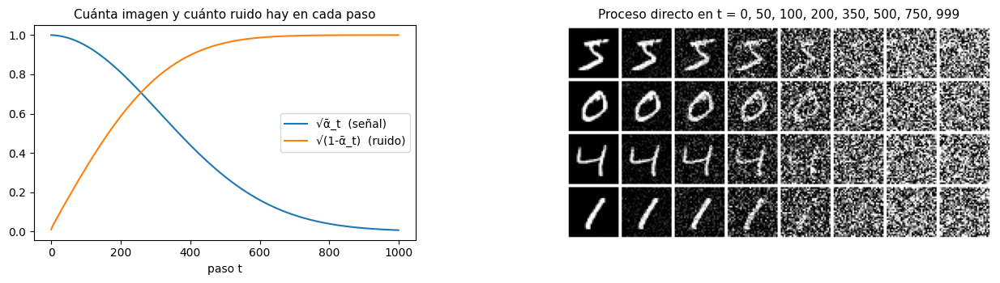

In [21]:
T_DIF = 1000                                                          # número de pasos de ruido
betas = torch.linspace(1e-4, 0.02, T_DIF, device=device)              # varianza del ruido añadido en cada paso
alphas = 1.0 - betas                                                  # fracción de señal conservada en cada paso
abar = torch.cumprod(alphas, dim=0)                                   # ᾱ_t: señal acumulada hasta el paso t

def q_muestrear(x0, t, ruido):
    """Salta directamente de la imagen limpia x0 al paso t: x_t = √ᾱ_t·x0 + √(1-ᾱ_t)·ε"""
    a = abar[t].view(-1, 1, 1, 1)                                     # ᾱ_t con forma para multiplicar imágenes
    return a.sqrt() * x0 + (1 - a).sqrt() * ruido

fig, axes = plt.subplots(1, 2, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 2.2]})
tt = np.arange(T_DIF)
axes[0].plot(tt, abar.sqrt().cpu(), label="√ᾱ_t  (señal)"); axes[0].plot(tt, (1 - abar).sqrt().cpu(), label="√(1-ᾱ_t)  (ruido)")
axes[0].set_xlabel("paso t"); axes[0].legend(); axes[0].set_title("Cuánta imagen y cuánto ruido hay en cada paso")
pasos_vis = [0, 50, 100, 200, 350, 500, 750, 999]
x0 = X_train[:4]
fila = [q_muestrear(x0, torch.full((4,), t, device=device), torch.randn_like(x0)) for t in pasos_vis]
mosaico = torch.stack(fila, 1).reshape(-1, 1, 32, 32)                # filas = imágenes, columnas = pasos
mostrar(mosaico, nrow=len(pasos_vis), ax=axes[1], titulo="Proceso directo en t = " + ", ".join(map(str, pasos_vis)))
plt.tight_layout(); plt.show()

## ¿Qué aprende?

Un predictor de ruido $\varepsilon_\theta(x_t,t,y)$, normalmente una U-Net: "dada esta imagen ruidosa, el nivel de ruido $t$ y la etiqueta, ¿qué ruido se le añadió?". Si sabemos el ruido, podemos restarlo. Equivalentemente la red aprende la dirección hacia imágenes más probables (el score, $\nabla_x\log p_t(x)$).

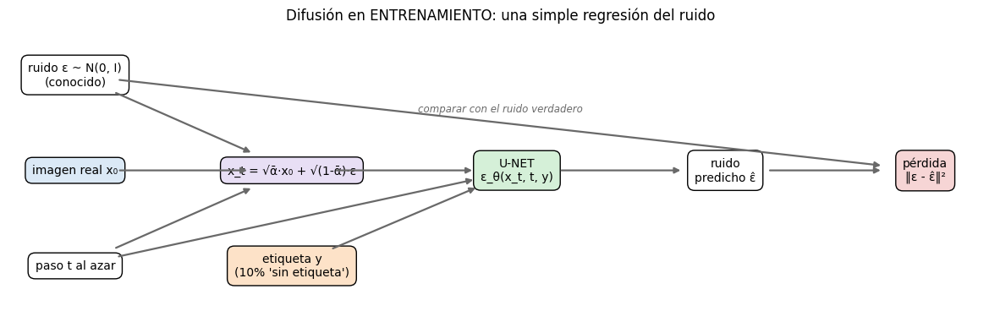

In [22]:
diagrama(
    {"x0": (0, 0, "imagen real x₀", "#dbe9f6"), "eps": (0, 1.4, "ruido ε ~ N(0, I)\n(conocido)", "white"),
     "t": (0, -1.4, "paso t al azar", "white"), "xt": (2.6, 0, "x_t = √ᾱ·x₀ + √(1-ᾱ)·ε", "#e8dff5"),
     "y": (2.6, -1.4, "etiqueta y\n(10% 'sin etiqueta')", "#fde2c8"), "U": (5.3, 0, "U-NET\nε_θ(x_t, t, y)", "#d5f0d8"),
     "eh": (7.8, 0, "ruido\npredicho ε̂", "white"), "L": (10.2, 0, "pérdida\n‖ε - ε̂‖²", "#f6d5d5")},
    [("x0", "xt", ""), ("eps", "xt", ""), ("t", "xt", ""), ("xt", "U", ""), ("y", "U", ""), ("t", "U", ""),
     ("U", "eh", ""), ("eh", "L", ""), ("eps", "L", "comparar con el ruido verdadero")],
    "Difusión en ENTRENAMIENTO: una simple regresión del ruido", tam=(15, 4.4))

## ¿Cómo aprende?

Con una regresión sorprendentemente simple:
$$
\mathcal L=\mathbb E_{x_0,\,y,\,t,\,\varepsilon}\Big[\big\lVert \varepsilon-\varepsilon_\theta\big(\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\,\varepsilon,\;t,\;y\big)\big\rVert^2\Big]
$$
Tomamos una imagen, un paso $t$ y un ruido al azar; le agregamos ruido a la imagen; pedimos a la red que recupere el ruido.

- Para qué sirve la pérdida: si la red sabe qué ruido tiene una imagen en cualquier nivel, sabe cómo limpiarla un poco en cualquier nivel, y encadenando esas limpiezas se genera desde ruido puro. Esta pérdida es una versión simplificada de una cota variacional de $-\log p_\theta(x)$, parecida a la ELBO del VAE.
- Por qué es diferenciable y estable: el ruido $\varepsilon$ y el paso $t$ se sortean antes de pasar por la red, así que no dependen de los parámetros; lo único que depende de $\theta$ es la salida de la U-Net, y el error cuadrático es la pérdida más suave que existe. No hay adversario ni colapso: se entrena como un problema supervisado normal.
- Condicionamiento y guía sin clasificador (CFG): la etiqueta entra sumada al embedding del tiempo. El 10% de las veces la reemplazamos por un símbolo especial "sin etiqueta" (el índice 10), así una sola red aprende a la vez el modelo condicional y el incondicional. Al generar combinamos ambas predicciones:
$$\tilde\varepsilon=\varepsilon_\theta(x_t,t,\varnothing)+w\,\big(\varepsilon_\theta(x_t,t,y)-\varepsilon_\theta(x_t,t,\varnothing)\big)$$
Con $w=0$ ignora la etiqueta, con $w=1$ es condicional puro y con $w>1$ exagera lo que distingue a la clase: dígitos más fieles a lo pedido a cambio de algo de variedad (`ESCALA_GUIA` en el panel de control).

In [23]:
def embedding_tiempo(t, dim):
    """Codifica el número de paso t como un vector de senos y cosenos (como las posiciones en un Transformer)."""
    mitad = dim // 2
    frecs = torch.exp(-math.log(10000) * torch.arange(mitad, device=t.device) / mitad)   # frecuencias geométricas
    args = t.float()[:, None] * frecs[None]                                                # (B, mitad)
    return torch.cat([args.sin(), args.cos()], dim=-1)                                     # (B, dim)

class BloqueRes(nn.Module):
    def __init__(self, c_in, c_out, dim_emb, dropout=0.1):
        super().__init__()
        self.norm1, self.conv1 = nn.GroupNorm(8, c_in), nn.Conv2d(c_in, c_out, 3, padding=1)
        self.emb = nn.Linear(dim_emb, c_out)                                  # (tiempo + etiqueta) -> un valor por canal
        self.norm2, self.conv2 = nn.GroupNorm(8, c_out), nn.Conv2d(c_out, c_out, 3, padding=1)
        self.drop = nn.Dropout(dropout)
        self.atajo = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()   # para sumar la entrada
    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))                                 # primera convolución
        h = h + self.emb(F.silu(emb))[:, :, None, None]                       # cada bloque "sabe" el nivel de ruido y la clase
        h = self.conv2(self.drop(F.silu(self.norm2(h))))                      # segunda convolución
        return h + self.atajo(x)                                              # conexión residual

class UNetCondicional(nn.Module):
    """U-Net compacta: 32×32 -> 16×16 -> 8×8 y de vuelta, con conexiones de salto."""
    def __init__(self, c1=64, c2=128, c3=256, dim_emb=256, n_clases=10):
        super().__init__()
        self.c1 = c1
        self.emb_t = nn.Sequential(nn.Linear(c1, dim_emb), nn.SiLU(), nn.Linear(dim_emb, dim_emb))   # tiempo -> vector
        self.emb_y = nn.Embedding(n_clases + 1, dim_emb)                      # 10 dígitos + 1 "sin etiqueta"
        self.entrada = nn.Conv2d(1, c1, 3, padding=1)
        self.b1 = BloqueRes(c1, c1, dim_emb); self.bajar1 = nn.Conv2d(c1, c1, 3, stride=2, padding=1)   # 32 -> 16
        self.b2 = BloqueRes(c1, c2, dim_emb); self.bajar2 = nn.Conv2d(c2, c2, 3, stride=2, padding=1)   # 16 -> 8
        self.b3 = BloqueRes(c2, c3, dim_emb)
        self.medio1, self.medio2 = BloqueRes(c3, c3, dim_emb), BloqueRes(c3, c3, dim_emb)
        self.s3 = BloqueRes(c3 + c3, c2, dim_emb)
        self.subir2 = nn.Sequential(nn.Upsample(scale_factor=2), nn.Conv2d(c2, c2, 3, padding=1))       # 8 -> 16
        self.s2 = BloqueRes(c2 + c2, c1, dim_emb)
        self.subir1 = nn.Sequential(nn.Upsample(scale_factor=2), nn.Conv2d(c1, c1, 3, padding=1))       # 16 -> 32
        self.s1 = BloqueRes(c1 + c1, c1, dim_emb)
        self.salida = nn.Sequential(nn.GroupNorm(8, c1), nn.SiLU(), nn.Conv2d(c1, 1, 3, padding=1))

    def forward(self, x, t, y):
        emb = self.emb_t(embedding_tiempo(t, self.c1)) + self.emb_y(y)        # tiempo + etiqueta en un solo vector
        h1 = self.b1(self.entrada(x), emb)                                    # 32×32
        h2 = self.b2(self.bajar1(h1), emb)                                    # 16×16
        h3 = self.b3(self.bajar2(h2), emb)                                    # 8×8
        m = self.medio2(self.medio1(h3, emb), emb)                            # cuello de botella
        u = self.s3(torch.cat([m, h3], 1), emb)                               # subimos, pegando lo que guardamos al bajar
        u = self.s2(torch.cat([self.subir2(u), h2], 1), emb)
        u = self.s1(torch.cat([self.subir1(u), h1], 1), emb)
        return self.salida(u)                                                 # ruido predicho, mismo tamaño que x

SIN_ETIQUETA = 10                                                             # índice del símbolo "sin etiqueta"
P_SIN_ETIQUETA = 0.1                                                          # probabilidad de ocultar la etiqueta al entrenar
fijar_semilla(0)
unet = UNetCondicional().to(device)
unet_ema = copy.deepcopy(unet).eval().requires_grad_(False)                   # copia con media móvil de los pesos
opt_dif = torch.optim.AdamW(unet.parameters(), lr=CONFIG["difusion"]["lr"])
usar_amp = device.type == "cuda"                                              # precisión mixta (fp16) en GPU
escalador = torch.amp.GradScaler("cuda", enabled=usar_amp)                    # evita que los gradientes fp16 se anulen
n_param_dif = sum(p.numel() for p in unet.parameters())
print(f"Parámetros de la U-Net: {n_param_dif / 1e6:.2f} M")

Parámetros de la U-Net: 5.48 M


## Entrenamiento paso a paso

Un paso de entrenamiento del modelo de difusión, con un lote de imágenes reales $x_0$ y sus etiquetas $y$, es:

1. **Sortear un nivel de ruido** $t$ entre 0 y 999 para cada imagen.
2. **Sortear el ruido** $\varepsilon\sim\mathcal N(0,I)$, del mismo tamaño que la imagen.
3. **Agregar ruido a la imagen de un salto:** $x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\varepsilon$.
4. **Ocultar la etiqueta** el 10% de las veces (se reemplaza por "sin etiqueta"), para poder usar la guía al generar.
5. **Predecir el ruido.** La U-Net recibe $(x_t, t, y)$ y devuelve $\hat\varepsilon$, su estimación del ruido que se añadió.
6. **Calcular la pérdida:** el error cuadrático $\lVert\varepsilon-\hat\varepsilon\rVert^2$.
7. **Retropropagar y actualizar** los pesos, igual que en el VAE, y actualizar la copia EMA.

Fíjate en lo que no pasa: durante el entrenamiento nunca se genera una imagen ni se recorren los 1000 pasos. Cada imagen se entrena en un único nivel de ruido elegido al azar. Veamos los pasos 1 a 6 con la red todavía aleatoria:

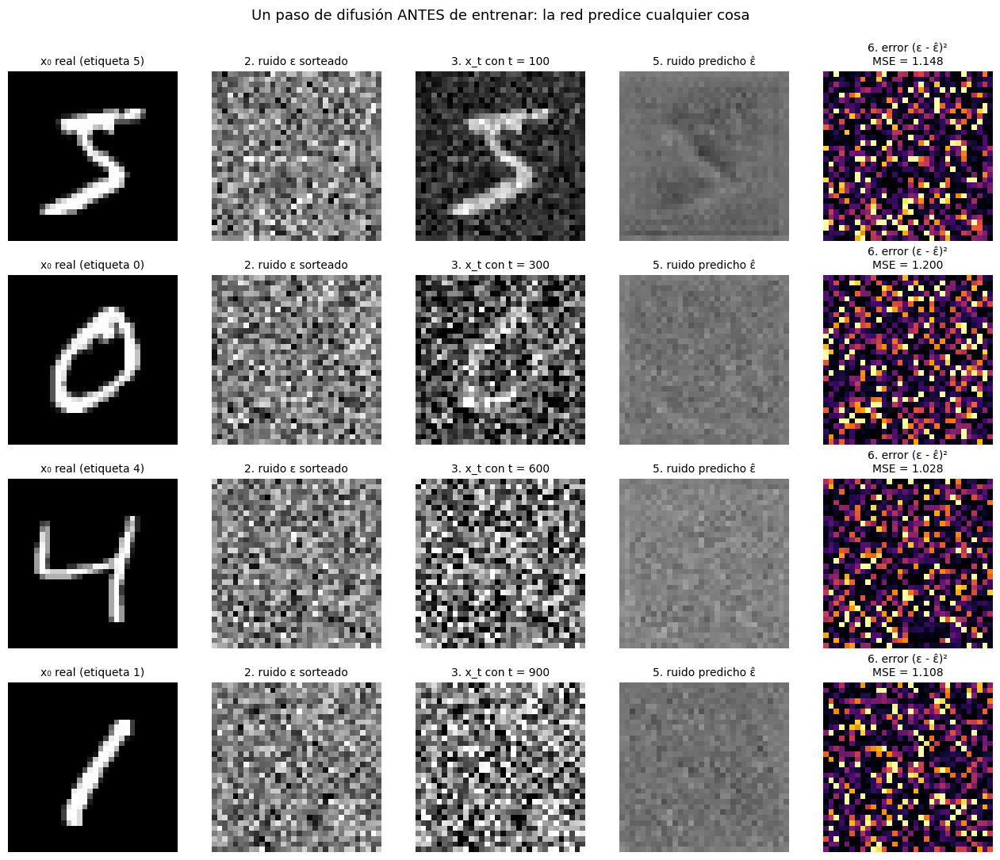

In [24]:
def anatomia_paso_difusion(red, x0, y, t, ruido, titulo):
    """Muestra los pasos 1 a 6 de un paso de entrenamiento de difusión, imagen por imagen."""
    with torch.no_grad():
        xt = q_muestrear(x0, t, ruido)                                     # paso 3: imagen con ruido
        pred = red(xt, t, y).float()                                       # paso 5: ruido predicho
        err = (ruido - pred) ** 2                                          # paso 6: error por píxel
    fig, axes = plt.subplots(len(x0), 5, figsize=(13, 2.7 * len(x0)))
    for i in range(len(x0)):
        paneles = [(x0[i], f"x₀ real (etiqueta {y[i].item()})"), (ruido[i] / 2.5, "2. ruido ε sorteado"),
                   (xt[i].clamp(-2.5, 2.5) / 1.5, f"3. x_t con t = {t[i].item()}"), (pred[i] / 2.5, "5. ruido predicho ε̂")]
        for c, (img, nombre) in enumerate(paneles):
            axes[i, c].imshow(a_imagen(img)); axes[i, c].axis("off"); axes[i, c].set_title(nombre, fontsize=10)
        axes[i, 4].imshow(err[i, 0].cpu(), cmap="inferno", vmin=0, vmax=4); axes[i, 4].axis("off")
        axes[i, 4].set_title(f"6. error (ε - ε̂)²\nMSE = {err[i].mean().item():.3f}", fontsize=10)
    plt.suptitle(titulo, fontsize=13, y=1.0); plt.tight_layout(); plt.show()

x0_demo, y_demo = X_train[:4], Y_train[:4]                                 # 4 imágenes fijas
t_demo = torch.tensor([100, 300, 600, 900], device=device)                 # paso 1: niveles de ruido (fijos para comparar)
ruido_demo = torch.randn_like(x0_demo)                                     # paso 2: ruido fijo
unet.eval()
anatomia_paso_difusion(unet, x0_demo, y_demo, t_demo, ruido_demo,
                       "Un paso de difusión ANTES de entrenar: la red predice cualquier cosa")

El paso 7 es idéntico al del VAE: retropropagar y actualizar. Hagamos uno solo y midamos la pérdida del mismo lote antes y después:

In [25]:
x0, y = X_train[:128], Y_train[:128]                                       # un lote fijo
t = torch.randint(0, T_DIF, (128,), device=device)                         # paso 1
ruido = torch.randn_like(x0)                                               # paso 2
unet.train()
perdida = F.mse_loss(unet(q_muestrear(x0, t, ruido), t, y), ruido)         # pasos 3, 5 y 6
opt_dif.zero_grad(set_to_none=True)
perdida.backward()                                                         # paso 7a: gradientes
opt_dif.step()                                                             # paso 7b: actualización
with torch.no_grad():
    nueva = F.mse_loss(unet(q_muestrear(x0, t, ruido), t, y), ruido)
print(f"MSE del lote antes del paso: {perdida.item():.4f} | después: {nueva.item():.4f}")

MSE del lote antes del paso: 1.1568 | después: 1.1370


Ahora repetimos ese ciclo miles de veces. `paso_difusion` hace exactamente los pasos 1 a 7 (con precisión mixta para ir más rápido) y `generar_difusion` es el procedimiento de generación que veremos paso a paso más abajo.

Durante el entrenamiento guardamos también una media móvil exponencial (EMA) de los pesos: promedia el ruido de los últimos pasos de optimización y mejora claramente las muestras. Es la copia que usamos para generar.

[Difusión condicional] 60,000 imágenes (100%), 468 pasos por época, meta: 8.0 min
     10% · paso    456 · época   1 ·    48 s · MSE del ruido 0.0320
     20% · paso    956 · época   3 ·    96 s · MSE del ruido 0.0247
     30% · paso   1438 · época   4 ·   144 s · MSE del ruido 0.0220
     40% · paso   1920 · época   5 ·   192 s · MSE del ruido 0.0210
     50% · paso   2407 · época   6 ·   240 s · MSE del ruido 0.0198
     60% · paso   2887 · época   7 ·   288 s · MSE del ruido 0.0194
     70% · paso   3368 · época   8 ·   336 s · MSE del ruido 0.0188
     80% · paso   3856 · época   9 ·   384 s · MSE del ruido 0.0188
     90% · paso   4334 · época  10 ·   432 s · MSE del ruido 0.0186
    100% · paso   4812 · época  11 ·   480 s · MSE del ruido 0.0183


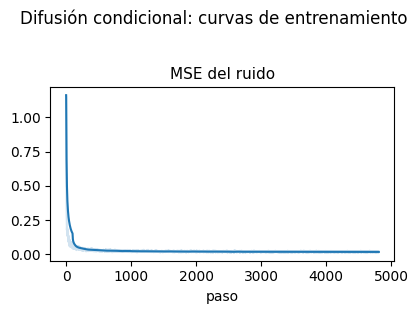

In [26]:
def paso_difusion(x0, y):
    unet.train()
    B = x0.size(0)
    t = torch.randint(0, T_DIF, (B,), device=device)                         # un nivel de ruido al azar por imagen
    ruido = torch.randn_like(x0)                                             # el ruido que añadiremos (lo conocemos)
    y_ent = torch.where(torch.rand(B, device=device) < P_SIN_ETIQUETA,
                        torch.full_like(y, SIN_ETIQUETA), y)                  # 10% de las veces ocultamos la etiqueta
    with torch.autocast("cuda", dtype=torch.float16, enabled=usar_amp):      # cálculos en fp16 (más rápido)
        pred = unet(q_muestrear(x0, t, ruido), t, y_ent)                     # la red intenta adivinar el ruido
    perdida = F.mse_loss(pred.float(), ruido)                                # error cuadrático con el ruido verdadero
    opt_dif.zero_grad(set_to_none=True)
    escalador.scale(perdida).backward()                                      # retropropagación (escalada para fp16)
    escalador.unscale_(opt_dif)                                              # deshacemos la escala antes de recortar
    nn.utils.clip_grad_norm_(unet.parameters(), 1.0)                         # evitamos pasos gigantes
    escalador.step(opt_dif); escalador.update()                              # actualizamos los pesos
    with torch.no_grad():                                                    # actualizamos la media móvil (EMA)
        d = min(0.999, (1 + len(hist_pasos)) / (10 + len(hist_pasos)))       # la EMA "arranca" rápido y luego se vuelve lenta
        for pe, p in zip(unet_ema.parameters(), unet.parameters()):
            pe.lerp_(p, 1 - d)                                               # pe = d·pe + (1-d)·p
    hist_pasos.append(1)
    return {"MSE del ruido": perdida.item()}

def predecir_ruido(red, x, t, y, w):
    """Guía sin clasificador: ε̃ = ε(sin etiqueta) + w·(ε(con etiqueta) - ε(sin etiqueta))."""
    tb = torch.full((len(x),), t, device=device)                             # el mismo paso para todo el lote
    if w == 1.0: return red(x, tb, y).float()                                # condicional puro: una sola pasada
    y_nulo = torch.full_like(y, SIN_ETIQUETA)
    e = red(torch.cat([x, x]), torch.cat([tb, tb]), torch.cat([y, y_nulo])).float()   # ambas predicciones en un lote
    e_cond, e_nulo = e.chunk(2)
    return e_nulo + w * (e_cond - e_nulo)

@torch.no_grad()
def generar_difusion(etiquetas, pasos=None, w=None, x_T=None, capturar=False):
    """Muestreador DDIM determinista (eta = 0)."""
    pasos = pasos or PASOS_DDIM; w = ESCALA_GUIA if w is None else w
    y = etiquetas.to(device)
    x = torch.randn(len(y), 1, 32, 32, device=device) if x_T is None else x_T.clone()   # partimos de ruido puro
    secuencia = torch.linspace(T_DIF - 1, 0, pasos).long().tolist()          # los pasos que visitaremos (999 ... 0)
    fotos_x, fotos_x0 = [], []
    for k, t in enumerate(secuencia):
        a_t = abar[t]                                                        # señal en el paso actual
        a_prev = abar[secuencia[k + 1]] if k + 1 < len(secuencia) else torch.tensor(1.0, device=device)   # señal en el siguiente
        with torch.autocast("cuda", dtype=torch.float16, enabled=usar_amp):
            eps = predecir_ruido(unet_ema, x, t, y, w)                       # ruido estimado (con guía)
        x0_hat = ((x - (1 - a_t).sqrt() * eps) / a_t.sqrt()).clamp(-1, 1)   # estimación de la imagen limpia
        eps = (x - a_t.sqrt() * x0_hat) / (1 - a_t).sqrt()                  # ruido coherente con el recorte
        x = a_prev.sqrt() * x0_hat + (1 - a_prev).sqrt() * eps              # saltamos al paso anterior
        if capturar: fotos_x.append(x.clamp(-1, 1).cpu()); fotos_x0.append(x0_hat.cpu())
    return (x.clamp(-1, 1).cpu(), fotos_x, fotos_x0) if capturar else x.clamp(-1, 1).cpu()

hist_pasos = []                                                              # contador de pasos para la EMA
X_T_GIF = torch.randn(4, 1, 32, 32, device=device)                           # ruido inicial fijo para seguir 4 imágenes
res_dif = entrenar("Difusión condicional", paso_difusion,
                   lambda: generar_difusion(ETIQ_GIF, x_T=X_T_GIF), CONFIG["difusion"])

Leyendo la curva: el error de predicción del ruido baja rápido y luego muy lentamente. Ojo: una pérdida que casi no baja no significa que el modelo no mejore; las muestras siguen mejorando mucho después, como se ve en la evolución.

### Evolución durante el entrenamiento

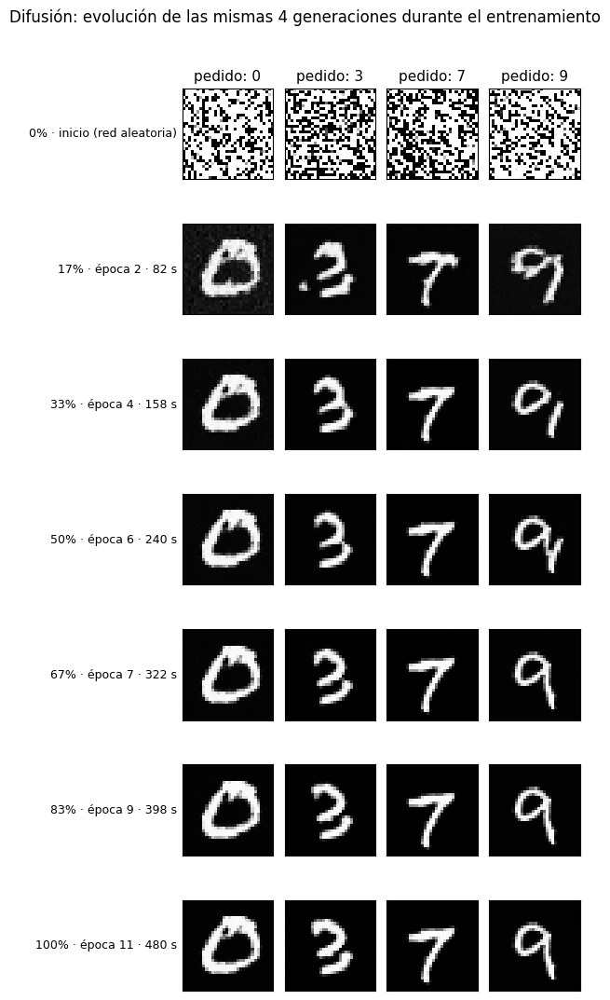

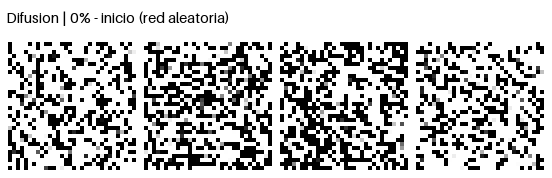

GIF guardado en: /kaggle/working/gifs/evolucion_difusion.gif


In [27]:
mostrar_evolucion(res_dif, "Difusión")
guardar_gif(res_dif["fotos"], [f"Difusion | {l}" for l in res_dif["leyendas"]], f"{TRABAJO}/gifs/evolucion_difusion.gif")

## Generación paso a paso

Generar es recorrer el proceso de ruido al revés. Con DDIM visitamos 50 niveles de ruido, de $t=999$ a $t=0$. En cada uno:

1. **Punto de partida.** La primera vez, $x_{999}$ es ruido puro $\mathcal N(0,I)$; después, es el resultado del paso anterior.
2. **Predecir el ruido con la etiqueta:** $\hat\varepsilon_{y}=\varepsilon_\theta(x_t,t,y)$.
3. **Predecir el ruido sin etiqueta:** $\hat\varepsilon_{\varnothing}=\varepsilon_\theta(x_t,t,\varnothing)$.
4. **Combinar con la guía:** $\tilde\varepsilon=\hat\varepsilon_{\varnothing}+w\,(\hat\varepsilon_{y}-\hat\varepsilon_{\varnothing})$. La diferencia $\hat\varepsilon_{y}-\hat\varepsilon_{\varnothing}$ es "lo que hace que sea un 7"; $w>1$ lo exagera.
5. **Estimar la imagen limpia:** $\hat x_0=(x_t-\sqrt{1-\bar\alpha_t}\,\tilde\varepsilon)/\sqrt{\bar\alpha_t}$. Es la "idea" que tiene la red del resultado final en este momento.
6. **Dar un paso hacia atrás:** $x_{t'}=\sqrt{\bar\alpha_{t'}}\,\hat x_0+\sqrt{1-\bar\alpha_{t'}}\,\tilde\varepsilon$, con $t'<t$ el siguiente nivel, un poco menos ruidoso.

Al llegar a $t=0$, $x_0$ es la imagen generada. En total son 50 pasadas por la red (100 con la guía, porque hacemos dos predicciones por paso).

La figura muestra los pasos 2 a 6 desarmados en tres momentos: al inicio (casi todo ruido), a la mitad y al final.

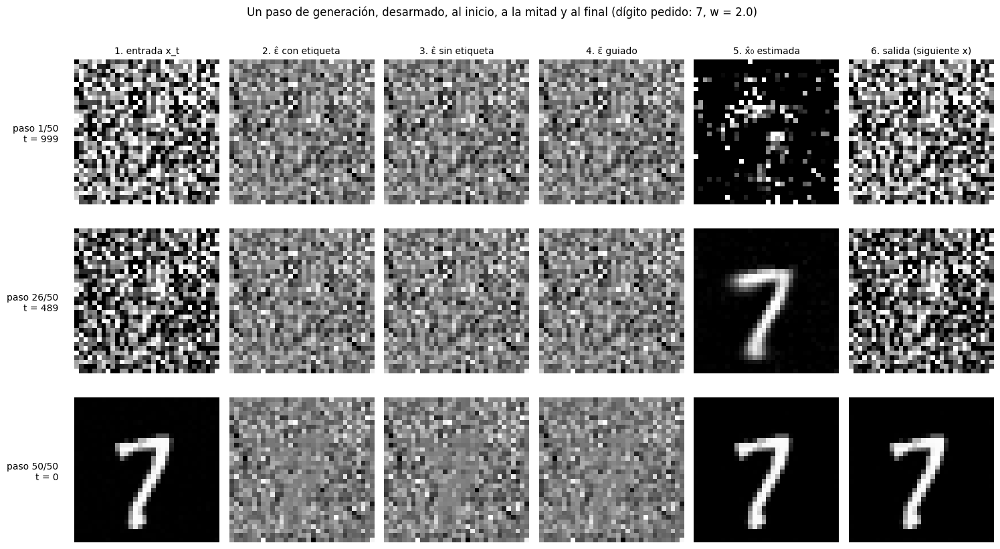

In [28]:
@torch.no_grad()
def un_paso_ddim(x, t, t_sig, y, w):
    """Un paso de generación DDIM, devolviendo todas sus partes intermedias."""
    tb = torch.full((len(x),), t, device=device)
    eps_y = unet_ema(x, tb, y).float()                                     # paso 2: con etiqueta
    eps_nulo = unet_ema(x, tb, torch.full_like(y, SIN_ETIQUETA)).float()   # paso 3: sin etiqueta
    eps = eps_nulo + w * (eps_y - eps_nulo)                                # paso 4: guía
    a_t = abar[t]
    a_sig = abar[t_sig] if t_sig >= 0 else torch.tensor(1.0, device=device)
    x0_hat = ((x - (1 - a_t).sqrt() * eps) / a_t.sqrt()).clamp(-1, 1)     # paso 5: imagen limpia estimada
    eps = (x - a_t.sqrt() * x0_hat) / (1 - a_t).sqrt()
    x_sig = a_sig.sqrt() * x0_hat + (1 - a_sig).sqrt() * eps               # paso 6: siguiente nivel
    return dict(x=x, eps_y=eps_y, eps_nulo=eps_nulo, eps=eps, x0_hat=x0_hat, x_sig=x_sig)

y = torch.tensor([7], device=device)                                       # dígito pedido
x = torch.randn(1, 1, 32, 32, device=device)                               # paso 1: ruido puro
secuencia = torch.linspace(T_DIF - 1, 0, PASOS_DDIM).long().tolist()       # 999, ..., 0
registro = {}
for k, t in enumerate(secuencia):                                          # recorremos los 50 pasos
    t_sig = secuencia[k + 1] if k + 1 < len(secuencia) else -1
    partes = un_paso_ddim(x, t, t_sig, y, ESCALA_GUIA)
    if k in (0, PASOS_DDIM // 2, PASOS_DDIM - 1): registro[(k, t)] = partes
    x = partes["x_sig"]                                                    # el resultado es la entrada del siguiente paso

cols = [("x", "1. entrada x_t", 1.0), ("eps_y", "2. ε̂ con etiqueta", 2.5), ("eps_nulo", "3. ε̂ sin etiqueta", 2.5),
        ("eps", "4. ε̃ guiado", 2.5), ("x0_hat", "5. x̂₀ estimada", 1.0), ("x_sig", "6. salida (siguiente x)", 1.0)]
fig, axes = plt.subplots(len(registro), len(cols), figsize=(15, 2.8 * len(registro)))
for r, ((k, t), partes) in enumerate(registro.items()):
    for c, (clave, nombre, escala) in enumerate(cols):
        axes[r, c].imshow(a_imagen(partes[clave][0].clamp(-escala, escala) / escala)); axes[r, c].axis("off")
        axes[r, c].set_title(nombre if r == 0 else "", fontsize=10)
    axes[r, 0].text(-4, 16, f"paso {k + 1}/{PASOS_DDIM}\nt = {t}", ha="right", va="center", fontsize=10)
plt.suptitle(f"Un paso de generación, desarmado, al inicio, a la mitad y al final (dígito pedido: 7, w = {ESCALA_GUIA})", y=1.0)
plt.tight_layout(); plt.show()

### El proceso completo y sus dos perillas

1. El proceso inverso completo: de ruido puro a dígito, junto con la estimación $\hat x_0$ en cada paso (la "idea" que la red tiene del resultado final), también en GIF.
2. El efecto de la guía $w$ y del número de pasos: las dos decisiones que se toman al generar, sin volver a entrenar.

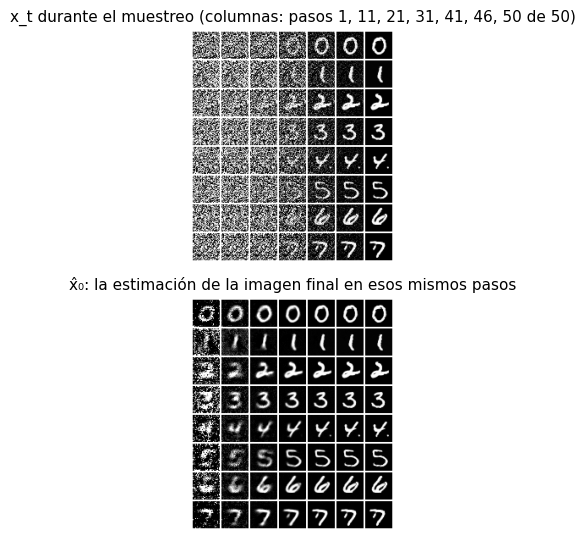

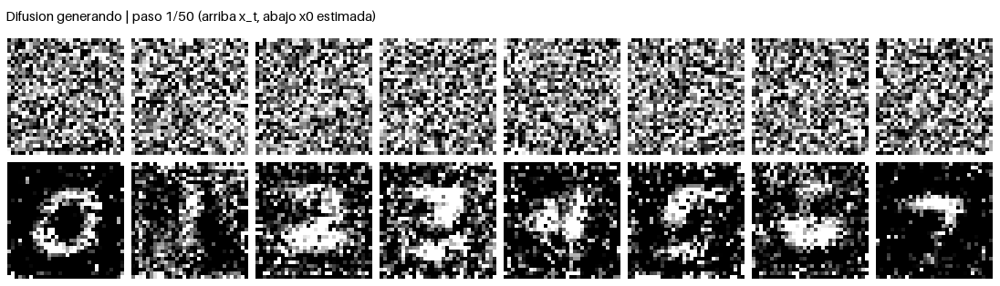

GIF guardado en: /kaggle/working/gifs/proceso_difusion.gif


In [29]:
final, fotos_x, fotos_x0 = generar_difusion(torch.arange(8), pasos=50, x_T=torch.randn(8, 1, 32, 32, device=device), capturar=True)
sel = [0, 10, 20, 30, 40, 45, 49]
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5))
mostrar(torch.stack([fotos_x[k] for k in sel], 1).reshape(-1, 1, 32, 32), nrow=len(sel), ax=axes[0],
        titulo="x_t durante el muestreo (columnas: pasos 1, 11, 21, 31, 41, 46, 50 de 50)")
mostrar(torch.stack([fotos_x0[k] for k in sel], 1).reshape(-1, 1, 32, 32), nrow=len(sel), ax=axes[1],
        titulo="x̂₀: la estimación de la imagen final en esos mismos pasos")
plt.tight_layout(); plt.show()
frames = [torch.cat([a, b]) for a, b in zip(fotos_x, fotos_x0)]               # arriba x_t, abajo x̂₀
guardar_gif(frames, [f"Difusion generando | paso {k + 1}/50 (arriba x_t, abajo x0 estimada)" for k in range(50)],
            f"{TRABAJO}/gifs/proceso_difusion.gif", ncol=8, ms=120)

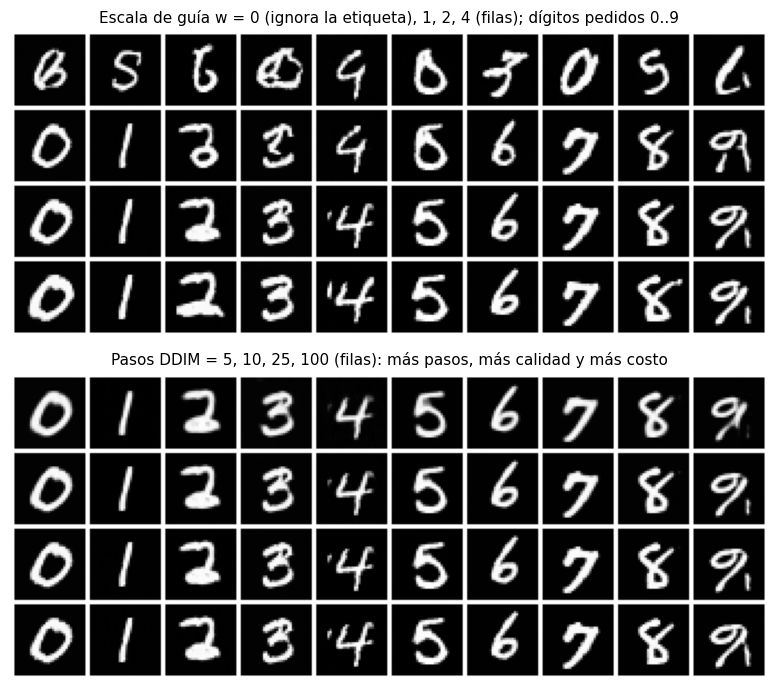

In [30]:
x_T = torch.randn(10, 1, 32, 32, device=device)                               # mismo ruido para todas las variantes
etiq = torch.arange(10)
fig, axes = plt.subplots(2, 1, figsize=(10, 7))
filas_w = [generar_difusion(etiq, w=w, x_T=x_T) for w in [0.0, 1.0, 2.0, 4.0]]
mostrar(torch.cat(filas_w), nrow=10, ax=axes[0], titulo="Escala de guía w = 0 (ignora la etiqueta), 1, 2, 4 (filas); dígitos pedidos 0..9")
filas_p = [generar_difusion(etiq, pasos=p, x_T=x_T) for p in [5, 10, 25, 100]]
mostrar(torch.cat(filas_p), nrow=10, ax=axes[1], titulo="Pasos DDIM = 5, 10, 25, 100 (filas): más pasos, más calidad y más costo")
plt.tight_layout(); plt.show()

## Evaluación cualitativa del modelo de difusión

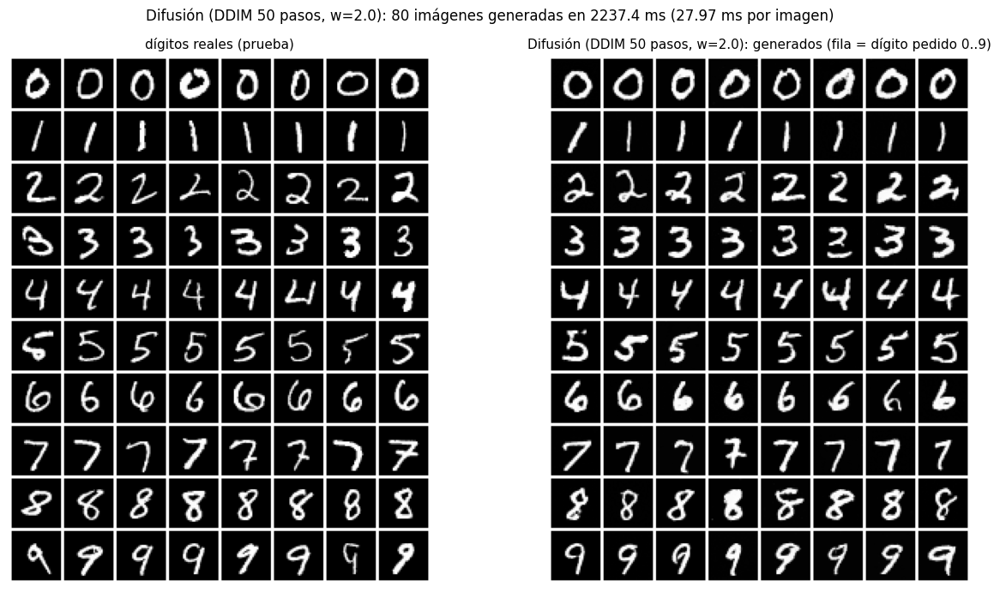

In [31]:
revisar_muestras(f"Difusión (DDIM {PASOS_DDIM} pasos, w={ESCALA_GUIA})", generar_difusion)
RES["Difusión"] = res_dif

Lo típico en difusión: trazos nítidos y variados, parecidos a los reales, y alta fidelidad a la etiqueta gracias a la guía. El costo es el tiempo: compara los segundos que tardó en generar frente al VAE.

# Comparación cualitativa entre VAE y difusión

Los dos modelos vieron los mismos datos (según el panel de control). Ahora los ponemos lado a lado y aplicamos los mismos criterios de revisión: ¿parece un dígito?, ¿es el pedido?, ¿hay variedad?, ¿es nítido?, ¿cuánto tarda?

## Las mismas peticiones a los dos modelos

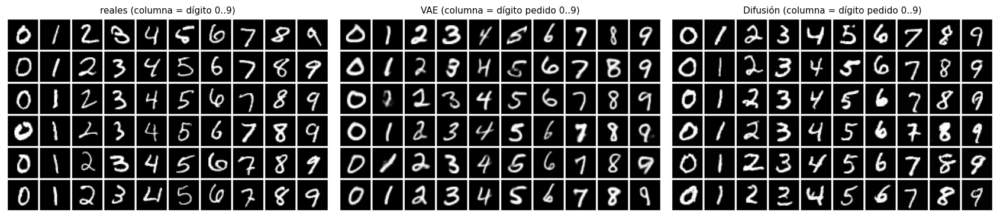

In [32]:
claves = {"VAE": "VAE", "Difusión": next(k for k in MUESTRAS if k.startswith("Difusión"))}
reales = torch.cat([X_test[Y_test == d][:6] for d in range(10)])           # 6 reales de cada dígito
fig, axes = plt.subplots(1, 3, figsize=(17, 6.2))
mostrar(reales.view(10, 6, 1, 32, 32).transpose(0, 1).reshape(-1, 1, 32, 32), nrow=10, ax=axes[0],
        titulo="reales (columna = dígito 0..9)")
for ax, (nombre, clave) in zip(axes[1:], claves.items()):
    e, imgs = MUESTRAS[clave]
    orden = torch.cat([torch.where(e == d)[0][:6] for d in range(10)])     # 6 muestras de cada dígito
    mostrar(imgs[orden].view(10, 6, 1, 32, 32).transpose(0, 1).reshape(-1, 1, 32, 32), nrow=10, ax=ax,
            titulo=f"{nombre} (columna = dígito pedido 0..9)")
plt.tight_layout(); plt.show()

## Dos formas de generar

La diferencia de fondo entre ambos modelos está en el proceso de generación. El VAE construye la imagen de una vez, ampliando un boceto de 4×4 hasta 32×32 dentro de una sola pasada por la red. La difusión parte de una imagen de ruido del tamaño final y la va limpiando en 50 pasadas.

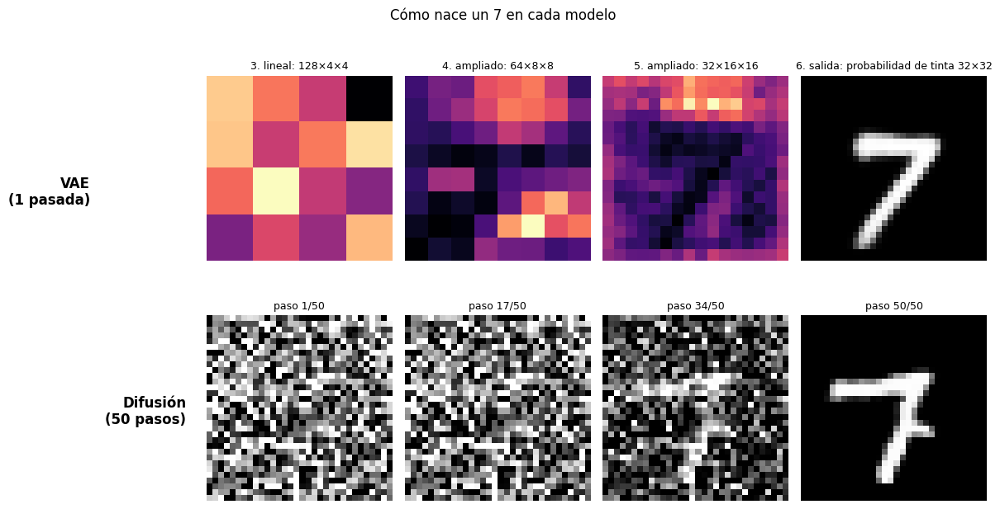

In [33]:
digito = 7
z = torch.randn(1, vae.dim_z, device=device)
etapas = etapas_decodificador(z, torch.tensor([digito]))                   # VAE: etapas dentro de una pasada
_, fotos_x, fotos_x0 = generar_difusion(torch.tensor([digito]), capturar=True)   # difusión: 50 pasadas
sel = np.linspace(0, len(fotos_x) - 1, len(etapas)).round().astype(int)

fig, axes = plt.subplots(2, len(etapas), figsize=(3 * len(etapas), 6.4))
for c, (nombre, h) in enumerate(etapas):
    mapa = h[0].mean(0).cpu() if h.shape[1] > 1 else h[0, 0].cpu()
    axes[0, c].imshow(mapa, cmap="magma" if h.shape[1] > 1 else "gray"); axes[0, c].axis("off")
    axes[0, c].set_title(nombre, fontsize=9)
    axes[1, c].imshow(a_imagen(fotos_x[sel[c]][0])); axes[1, c].axis("off")
    axes[1, c].set_title(f"paso {sel[c] + 1}/{len(fotos_x)}", fontsize=9)
axes[0, 0].text(-3, 2, "VAE\n(1 pasada)", ha="right", va="center", fontsize=12, fontweight="bold")
axes[1, 0].text(-4, 16, f"Difusión\n({len(fotos_x)} pasos)", ha="right", va="center", fontsize=12, fontweight="bold")
plt.suptitle(f"Cómo nace un {digito} en cada modelo", y=1.0); plt.tight_layout(); plt.show()

## Evolución de los dos modelos durante su entrenamiento

Cada fila es un modelo; las columnas son los mismos 4 dígitos pedidos (`DIGITOS_GIF`) con el mismo ruido de partida. El eje del tiempo está normalizado: cada cuadro corresponde al mismo porcentaje del entrenamiento de cada modelo.

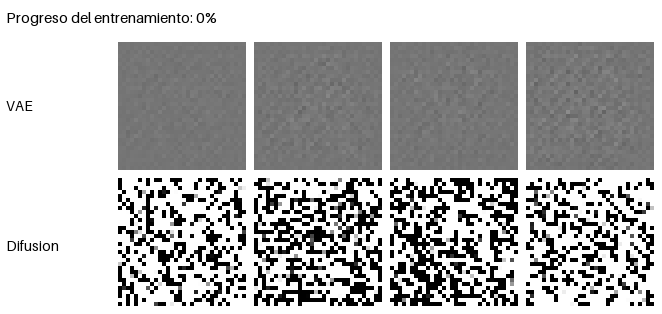

GIF guardado en: /kaggle/working/gifs/evolucion_vae_vs_difusion.gif


In [34]:
modelos = list(RES)
n_frames = N_SNAPSHOTS + 1
frames = []
for k in range(n_frames):
    fila = []
    for m in modelos:
        fotos = RES[m]["fotos"]
        fila.append(fotos[round(k * (len(fotos) - 1) / (n_frames - 1))])   # mismo porcentaje de avance
    frames.append(torch.cat(fila))
guardar_gif(frames, [f"Progreso del entrenamiento: {100 * k / (n_frames - 1):.0f}%" for k in range(n_frames)],
            f"{TRABAJO}/gifs/evolucion_vae_vs_difusion.gif", ncol=4, nombres_filas=modelos)

## Pídele un dígito a los dos modelos

Cambia `DIGITO_PEDIDO` y vuelve a ejecutar la celda.

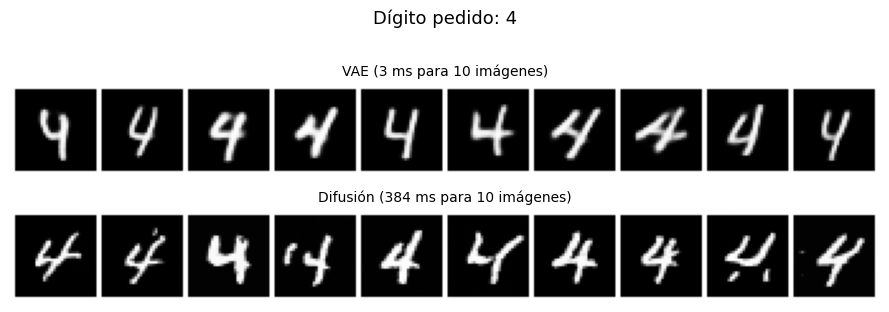

In [35]:
DIGITO_PEDIDO = 4          # <- elige un dígito del 0 al 9
N_MUESTRAS = 10            # cuántas versiones de ese dígito generar con cada modelo

generadores = {"VAE": generar_vae, "Difusión": generar_difusion}
etiq = torch.full((N_MUESTRAS,), DIGITO_PEDIDO)
fig, axes = plt.subplots(len(generadores), 1, figsize=(N_MUESTRAS * 0.9, 1.6 * len(generadores)))
for ax, (m, fn) in zip(axes, generadores.items()):
    t0 = time.time(); imgs = fn(etiq); dt = time.time() - t0
    mostrar(imgs, nrow=N_MUESTRAS, ax=ax); ax.set_title(f"{m} ({1000 * dt:.0f} ms para {N_MUESTRAS} imágenes)", fontsize=10)
plt.suptitle(f"Dígito pedido: {DIGITO_PEDIDO}", y=1.02, fontsize=13); plt.tight_layout(); plt.show()

## Conclusiones

Lo que muestran las imágenes cambia un poco entre ejecuciones, pero el patrón es muy estable:

| | VAE | Difusión |
|---|---|---|
| ¿Qué aprende? | Un codificador $q(z\mid x,y)$ y un decodificador $p(x\mid z,y)$ | Un predictor de ruido $\varepsilon_\theta(x_t,t,y)$ |
| ¿Cómo aprende? | Reconstrucción + KL (−ELBO), con reparametrización | Error cuadrático entre el ruido real y el predicho |
| Un paso de entrenamiento | Codificar → sortear ε → z → decodificar → pérdida → actualizar | Sortear t y ε → agregar ruido → predecir el ruido → pérdida → actualizar |
| ¿Cómo genera? | $z\sim\mathcal N(0,I)$ + etiqueta → decodificador, una pasada | Ruido puro → 50 pasos de quitar ruido, cada uno con dos predicciones |
| ¿Parece un dígito? ¿Es el pedido? | Sí, en general | Sí, en general (la guía ayuda) |
| Nitidez | Borroso | Nítido |
| Variedad | Buena | Buena |
| Velocidad de generación | Muy rápida | Decenas o cientos de veces más lenta |

La idea central: el VAE genera de una vez y paga en nitidez; la difusión genera gradualmente y paga en tiempo. Ambos entrenan de forma estable porque sus pérdidas son suaves y el azar queda fuera del camino del gradiente.

Ideas para seguir explorando (todas se controlan desde el panel de control o cambiando un número):
1. Entrena con `fraccion_datos=0.05` (3.000 imágenes). ¿Qué modelo sufre más con pocos datos?
2. Da a los dos modelos el mismo tiempo de entrenamiento. ¿Cambia la comparación?
3. Genera con `PASOS_DDIM` = 5, 10 y 200: ¿en qué momento empiezan a verse bien los dígitos?
4. Genera con `ESCALA_GUIA` = 0, 1 y 4: ¿qué pasa con la fidelidad a la etiqueta y con la variedad?
5. Cambia `dim_z` del VAE a 2 y vuelve a entrenar: ¿qué estilos logra representar con solo dos números?

Referencias
- Kingma & Welling, *Auto-Encoding Variational Bayes*, 2013 · Sohn et al., *Learning Structured Output Representation using Deep Conditional Generative Models* (CVAE), 2015.
- Ho, Jain & Abbeel, *Denoising Diffusion Probabilistic Models*, 2020 · Song, Meng & Ermon, *Denoising Diffusion Implicit Models*, 2020 · Ho & Salimans, *Classifier-Free Diffusion Guidance*, 2021.